# 16 · Does the real app avoid the JH dataset-crop problem?

**Yes on these seven development photos:** the same S1 reads the app crops much better than the supplied upright dataset crops. This notebook displays saved outputs; it starts no training, inference or downloads.

The unchanged path is **PP-OCRv5_mobile_det → existing grouping → existing quad crop → S1**. Reading-order work remains deferred. Matching uses image-only geometry and provisional line bands. Recognition scores concern matched dataset lines, not complete pages or unseen future writers.

In [1]:
from pathlib import Path
import json, html, re
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, HTML, Markdown, Image as IPImage
roots=[q for p in [Path.cwd(),*Path.cwd().parents] for q in (p,p/'Assignment')]
A=next(p for p in roots if (p/'claude_jh_fullphoto_20261109/RESULTS.json').is_file())
D=A/'claude_jh_fullphoto_20261109'
RUN=A/'whiteboard-ocr/outputs/jh_full_photos_app'
R=json.loads((D/'RESULTS.json').read_text()); S=R['summary']
CHECKS=json.loads((D/'CHECKS_CODEX.json').read_text())
def table(headers,rows):
    e=lambda x:html.escape(str(x))
    display(HTML('<table><tr>'+''.join('<th style="padding:8px">'+e(h)+'</th>' for h in headers)+'</tr>'+''.join('<tr>'+''.join('<td style="padding:8px;border-bottom:1px solid #ddd">'+e(v)+'</td>' for v in row)+'</tr>' for row in rows)+'</table>'))
arms=['original','tight','straightened','app']
table(['Input','Matched lines','Mean line CER','Deletions','Lines at >=15% CER'],[[k,S['n_one_to_one'],f"{S['cer_'+k]:.2%}",S['D_'+k],S['persist15_'+k]] for k in arms])
print('Model: S1 seed 1. Same reader object, all four input types. Original app unchanged.')

Input,Matched lines,Mean line CER,Deletions,Lines at >=15% CER
original,59,21.14%,232,29
tight,59,16.43%,187,22
straightened,59,5.37%,68,4
app,59,0.87%,5,0


Model: S1 seed 1. Same reader object, all four input types. Original app unchanged.


## 1. What this means

The recognizer did not suddenly learn new handwriting. It received better input from the existing detector/cropping path. The app cuts along tilted boxes, so the writing fills more of the resized image.

This comparison also changes source resolution and sampling: the full photos contain more pixels than the dataset crops. We cannot assign the entire benefit to one geometric mechanism. All 59 supplied lines matched, so none was silently dropped from this recognition table.

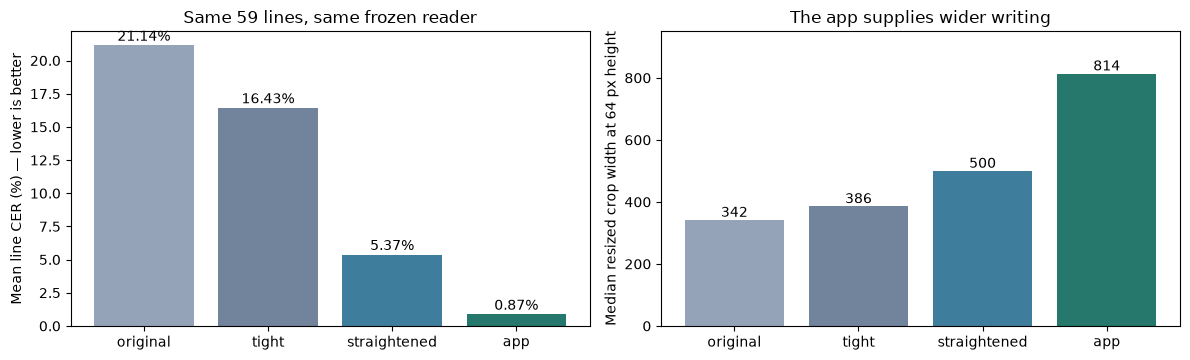

App minus dataset input,CER difference (pp),Photo-cluster 95% interval (pp),App better/worse
original,-20.27,-25.93 to -14.43,43 / 5
tight,-15.56,-21.44 to -9.89,39 / 5
straightened,-4.50,-6.70 to -2.10,20 / 3


In [2]:
fig,ax=plt.subplots(1,2,figsize=(12,3.7))
vals=[100*S['cer_'+k] for k in arms]
ax[0].bar(arms,vals,color=['#94a3b8','#71849c','#3f7d9c','#26786c'])
for i,y in enumerate(vals):ax[0].text(i,y+.35,f'{y:.2f}%',ha='center')
ax[0].set_ylabel('Mean line CER (%) — lower is better');ax[0].set_title('Same 59 lines, same frozen reader')
widths=[S['median_width64'][k] for k in arms]
ax[1].bar(arms,widths,color=['#94a3b8','#71849c','#3f7d9c','#26786c'])
for i,y in enumerate(widths):ax[1].text(i,y+10,f'{y:.0f}',ha='center')
ax[1].set_ylim(0,950);ax[1].set_ylabel('Median resized crop width at 64 px height');ax[1].set_title('The app supplies wider writing')
fig.tight_layout();plt.show()
table(['App minus dataset input','CER difference (pp)','Photo-cluster 95% interval (pp)','App better/worse'],[[k,f"{100*S['app_minus_'+k]['diff']:+.2f}",' to '.join(f'{100*v:+.2f}' for v in S['app_minus_'+k]['ci_photo_bootstrap']),f"{S['app_minus_'+k]['app_better']} / {S['app_minus_'+k]['app_worse']}"] for k in arms[:3]])

## 2. Detection outcomes stay separate from recognition

The raw detector splits one supplied line into two pieces; existing grouping repairs that split. Two other regions have no match in the dataset-line inventory. These outcomes are based on a heuristic geometric graph, not standard detector recall. A match does not prove every character stroke is covered.

All photos and all matched lines remain visible below. Grey bands in overlays are reference geometry; green means one-to-one association; blue is a split candidate; red is unmatched.

Photo,Dataset lines,Raw boxes,App regions,Raw outcomes,Grouped outcomes
1,9,9,9,{'one_to_one': 9},{'one_to_one': 9}
2,4,6,5,"{'split': 1, 'one_to_one': 3, 'extra_region': 1}","{'one_to_one': 4, 'extra_region': 1}"
3,8,8,8,{'one_to_one': 8},{'one_to_one': 8}
4,10,10,10,{'one_to_one': 10},{'one_to_one': 10}
5,10,11,11,"{'one_to_one': 10, 'extra_region': 1}","{'one_to_one': 10, 'extra_region': 1}"
6,8,8,8,{'one_to_one': 8},{'one_to_one': 8}
7,10,10,10,{'one_to_one': 10},{'one_to_one': 10}


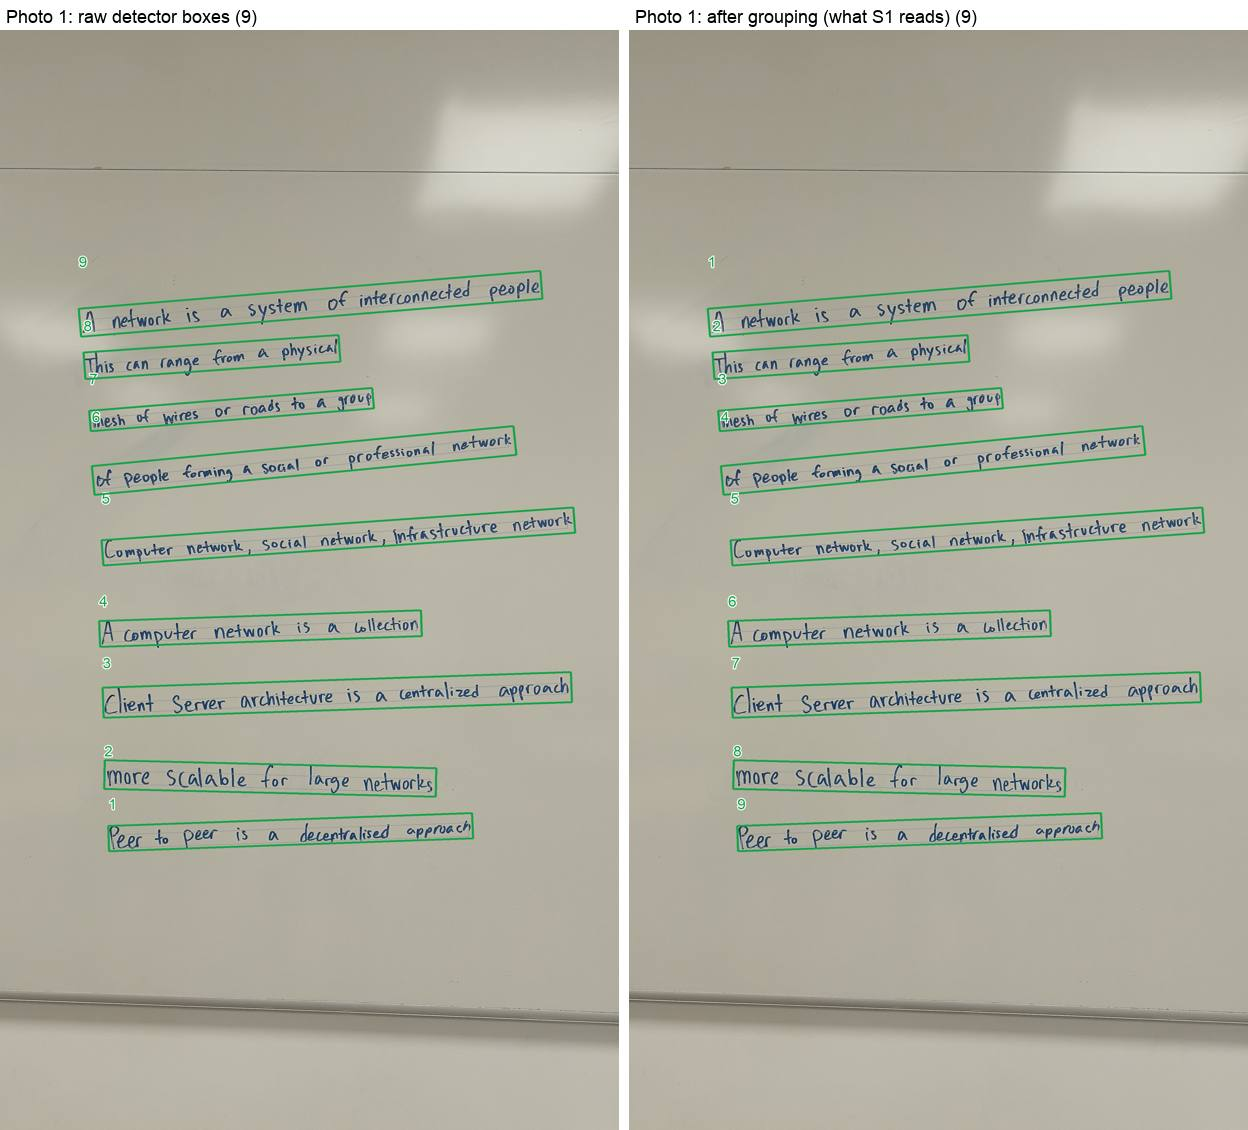

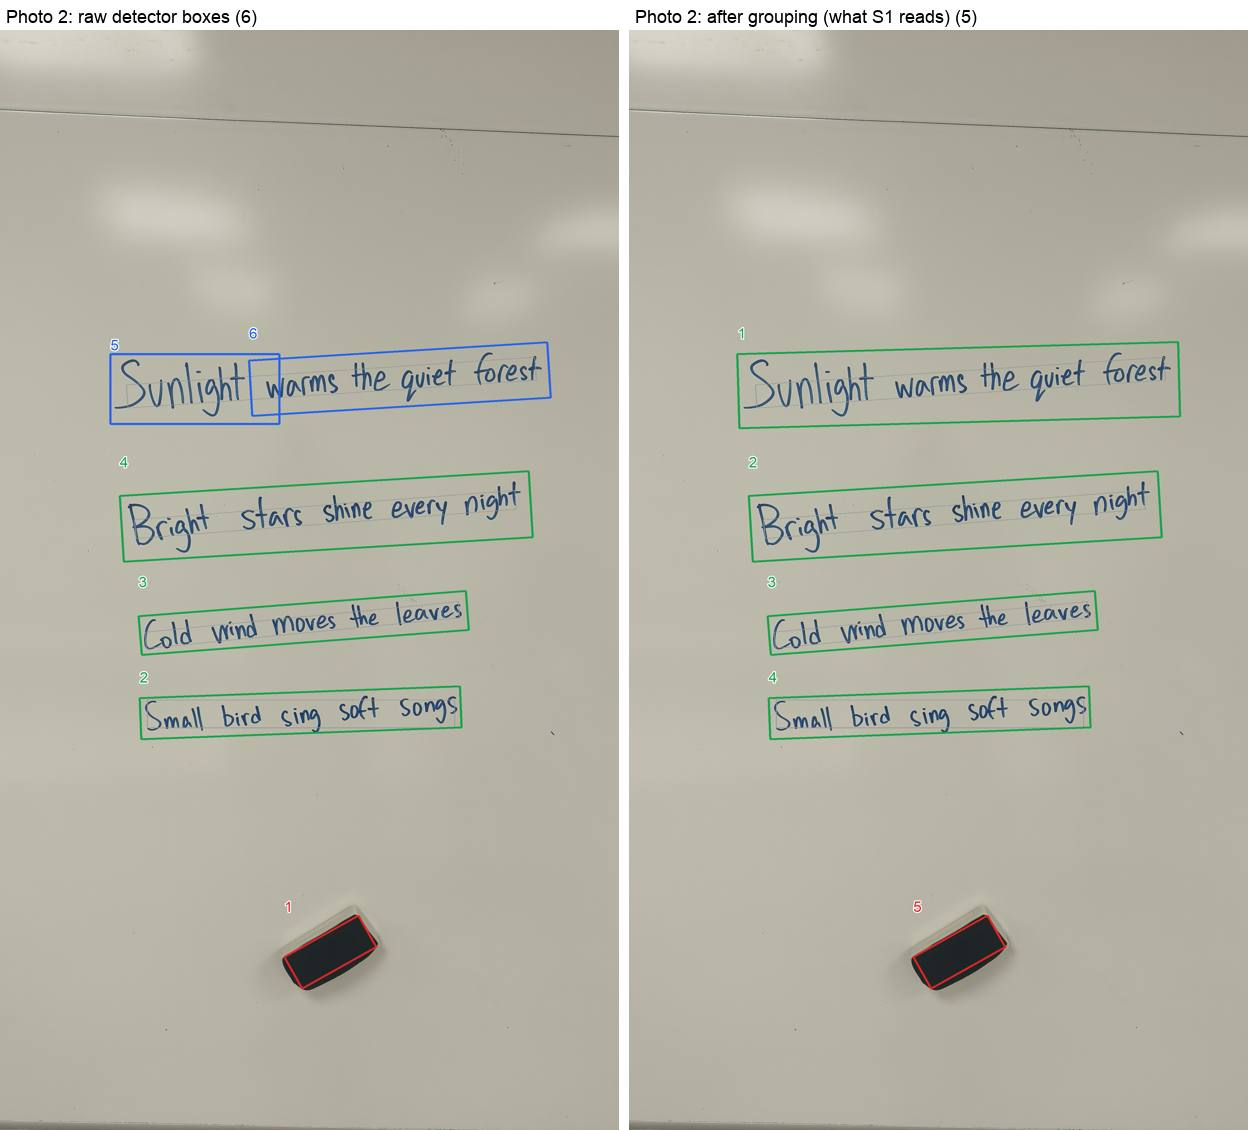

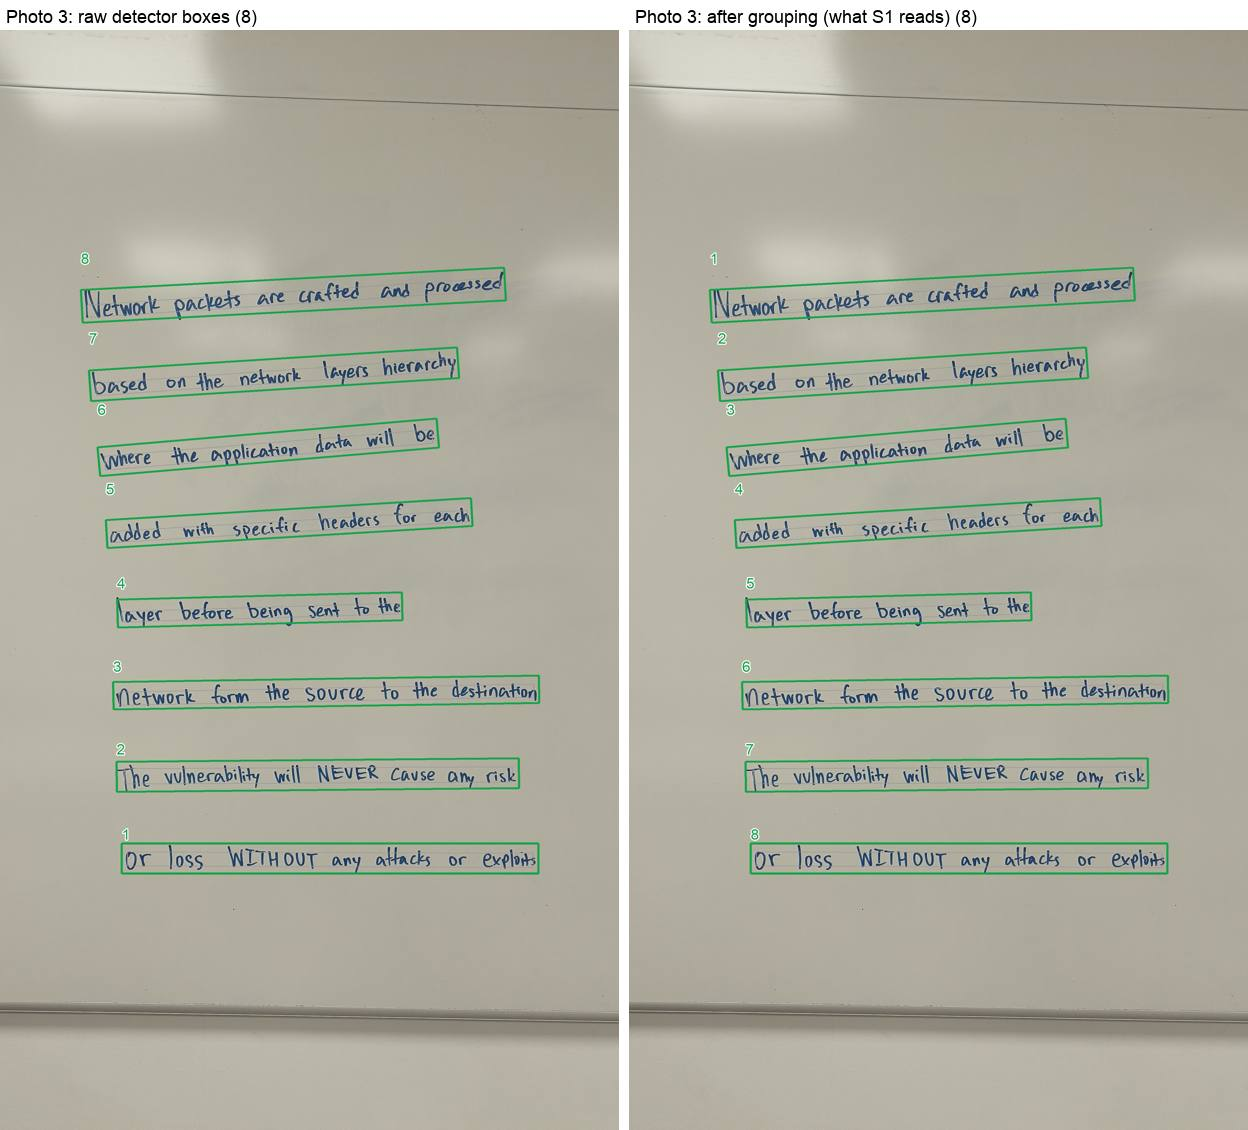

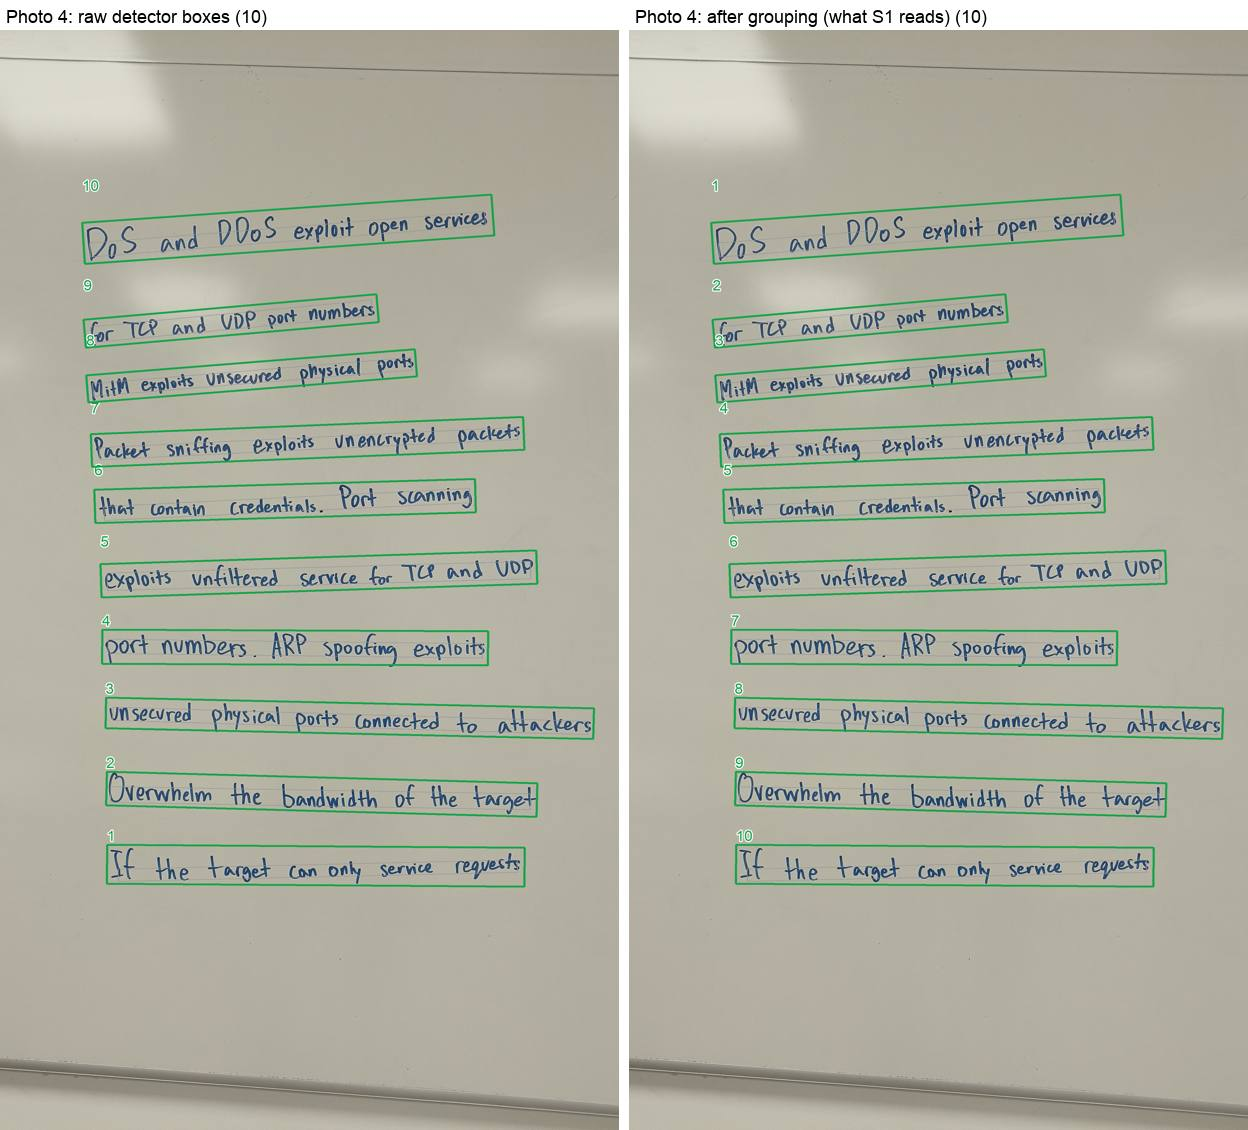

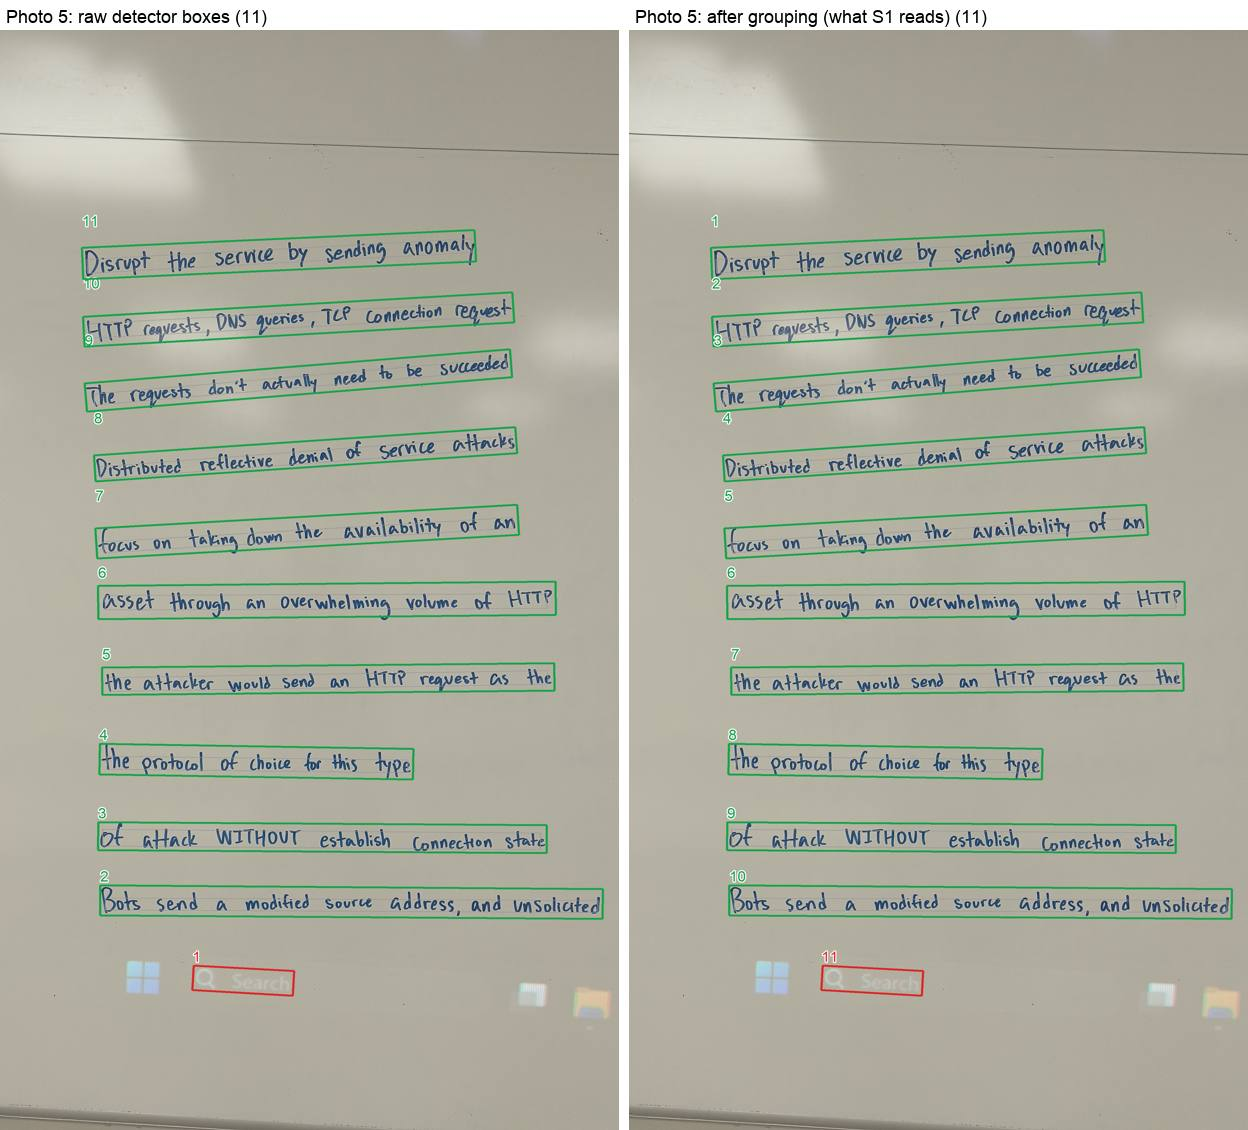

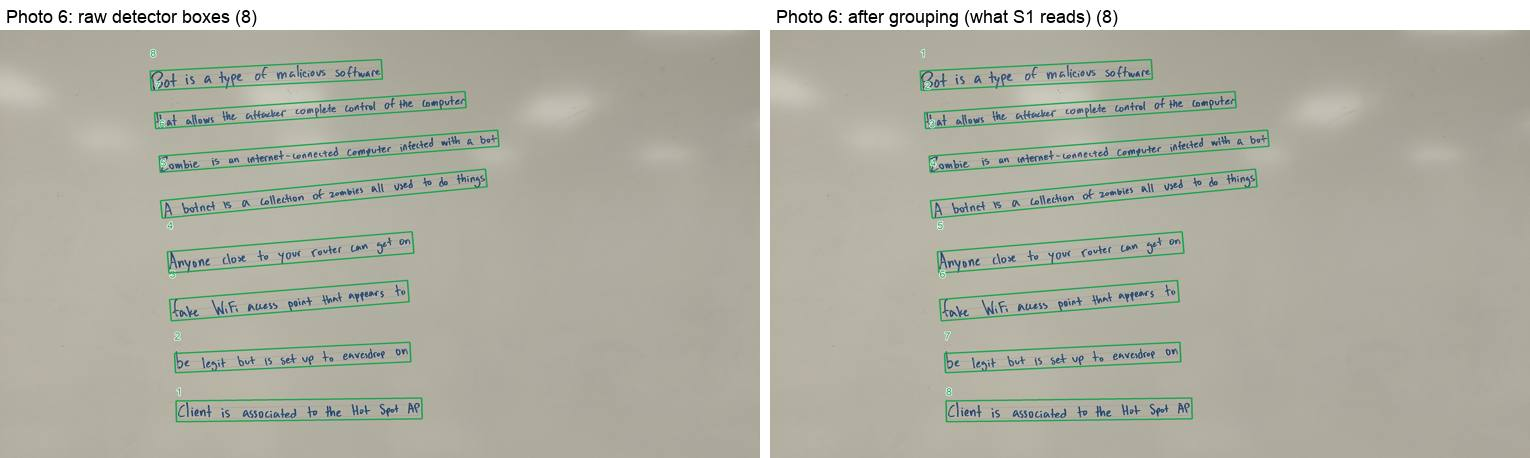

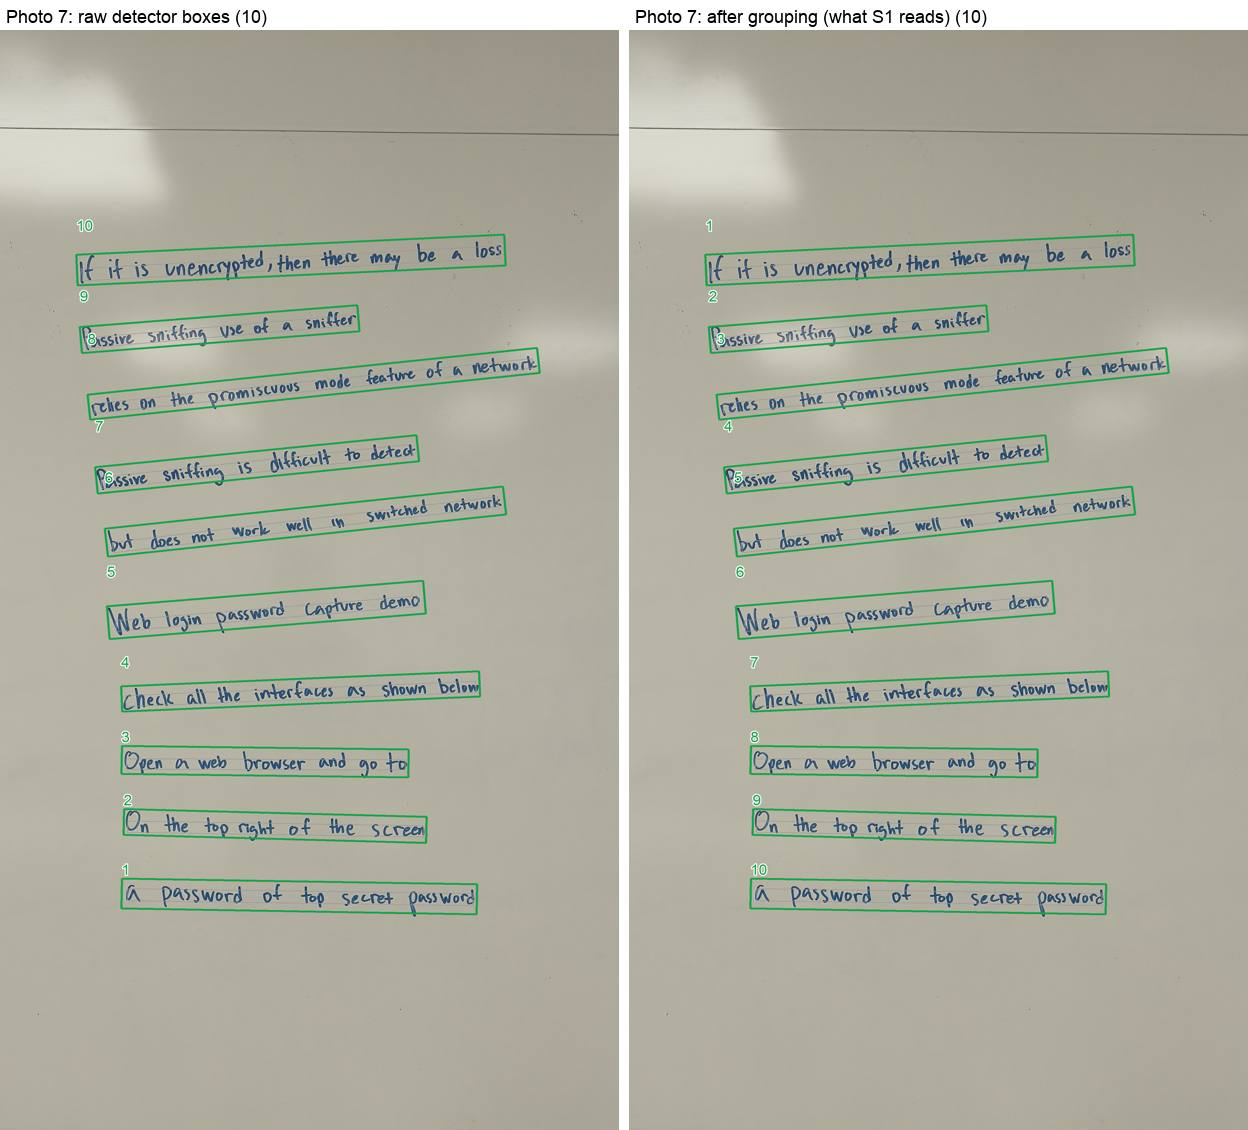

In [3]:
table(['Photo','Dataset lines','Raw boxes','App regions','Raw outcomes','Grouped outcomes'],[[pid,p['lines'],p['raw_boxes'],p['regions'],p['raw'],p['grouped']] for pid,p in R['per_photo'].items()])
for name in R['visuals']['overlays']:
    display(IPImage(filename=str(D/'visuals'/name),width=1100))

## 3. Every app crop and its actual reader input

Left: crop pixels cut from the original photo. Right: saved rendering of the actual normalised S1 input, including grey padding. Wide inputs are fitted for display, so the displayed height may be smaller than 64 px. The stored PNG has the actual tensor dimensions. Captions show complete saved text where space permits; use the exact-line viewer below for untruncated readings.

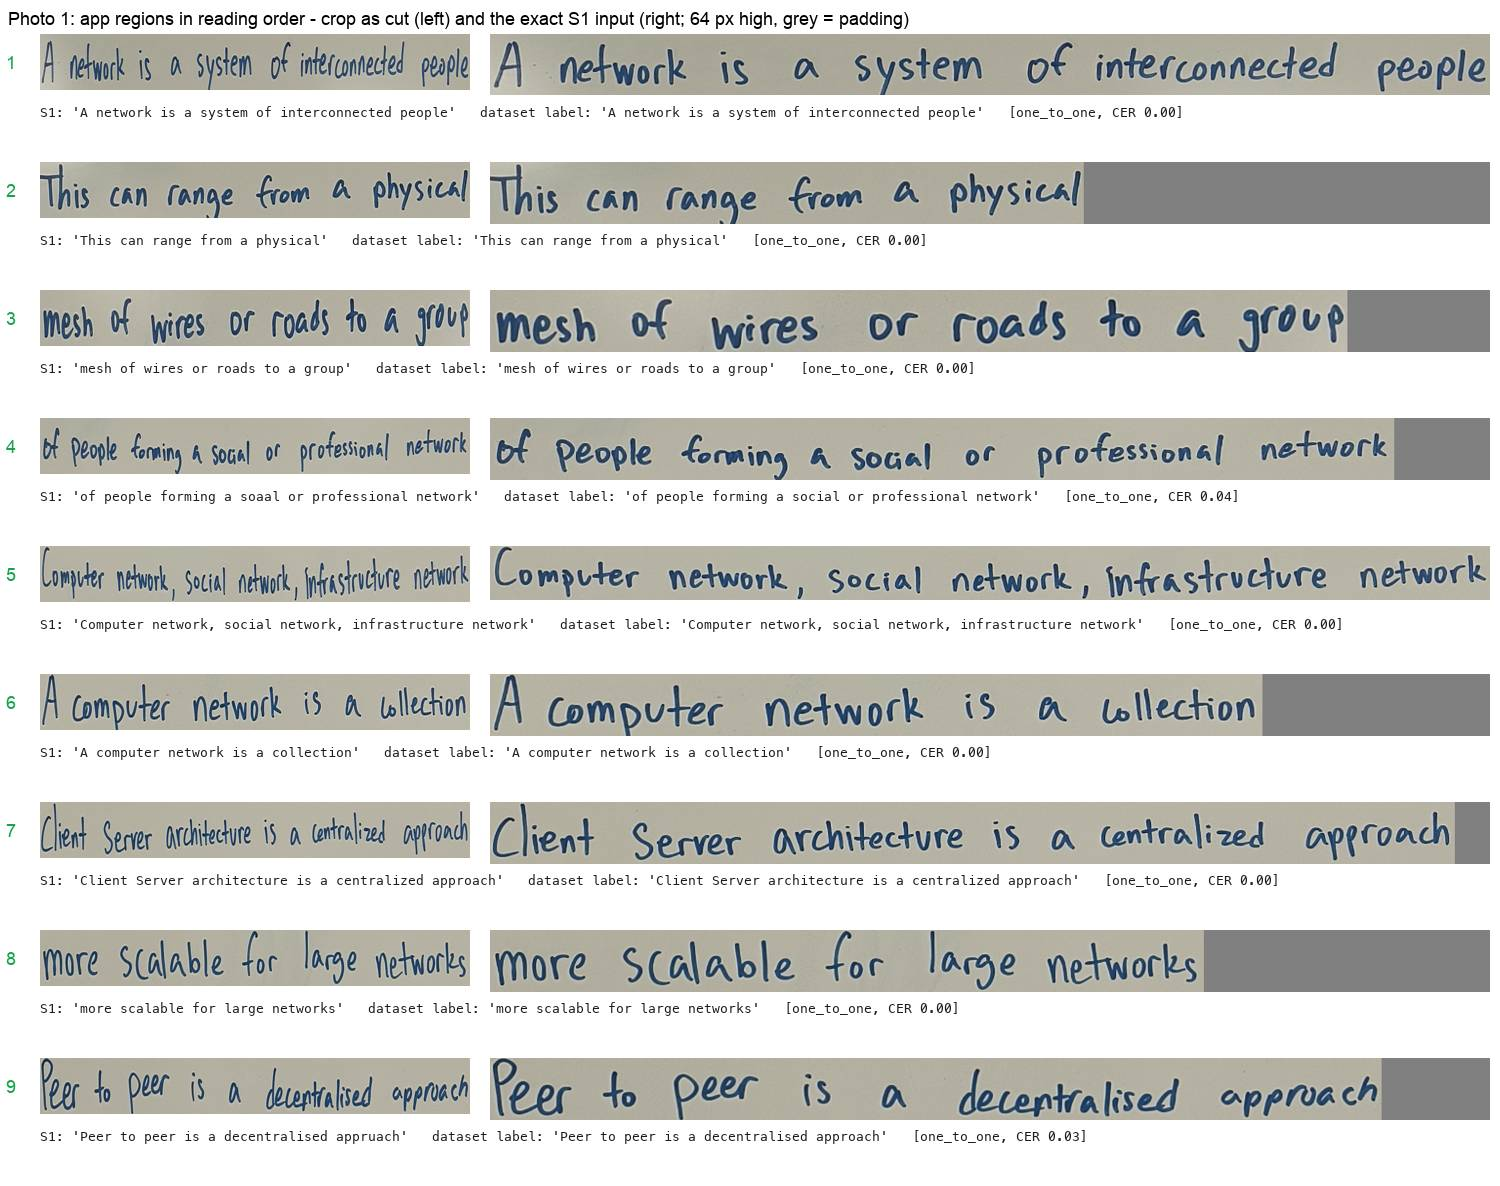

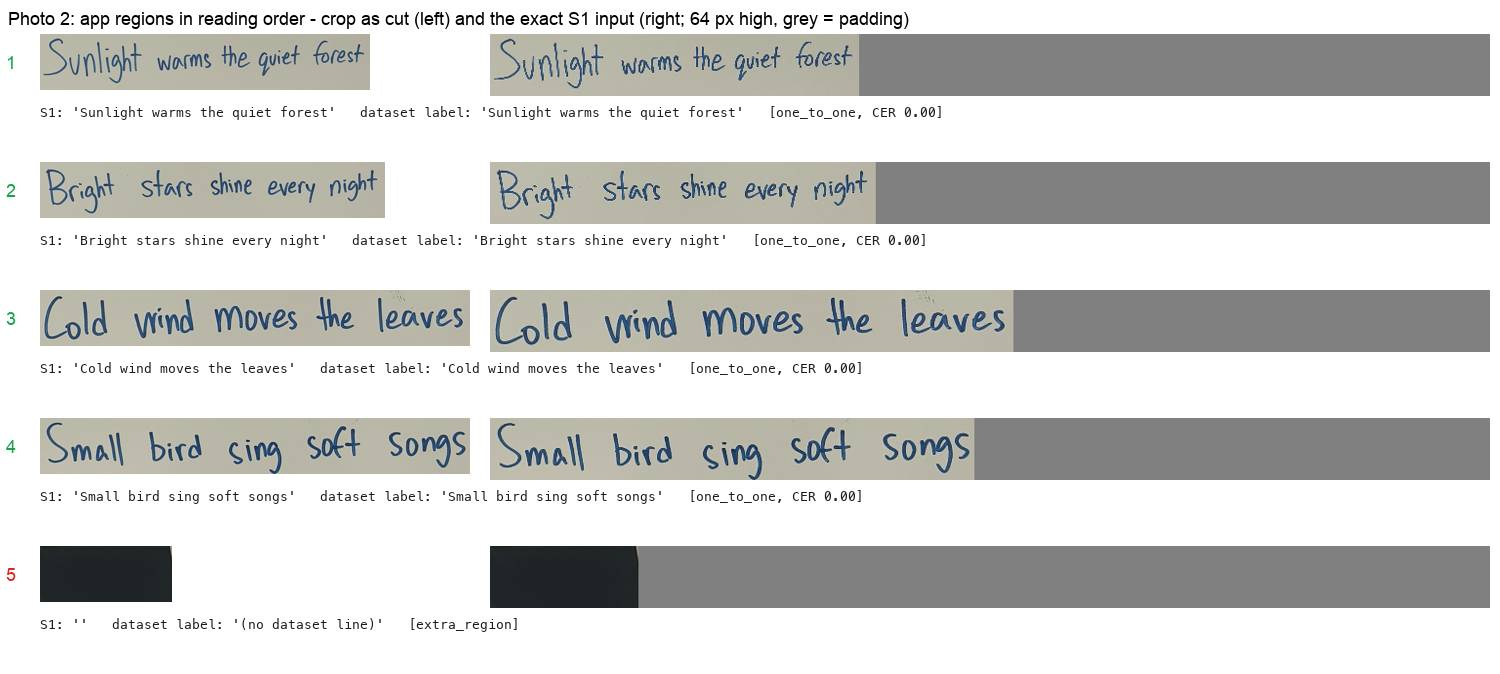

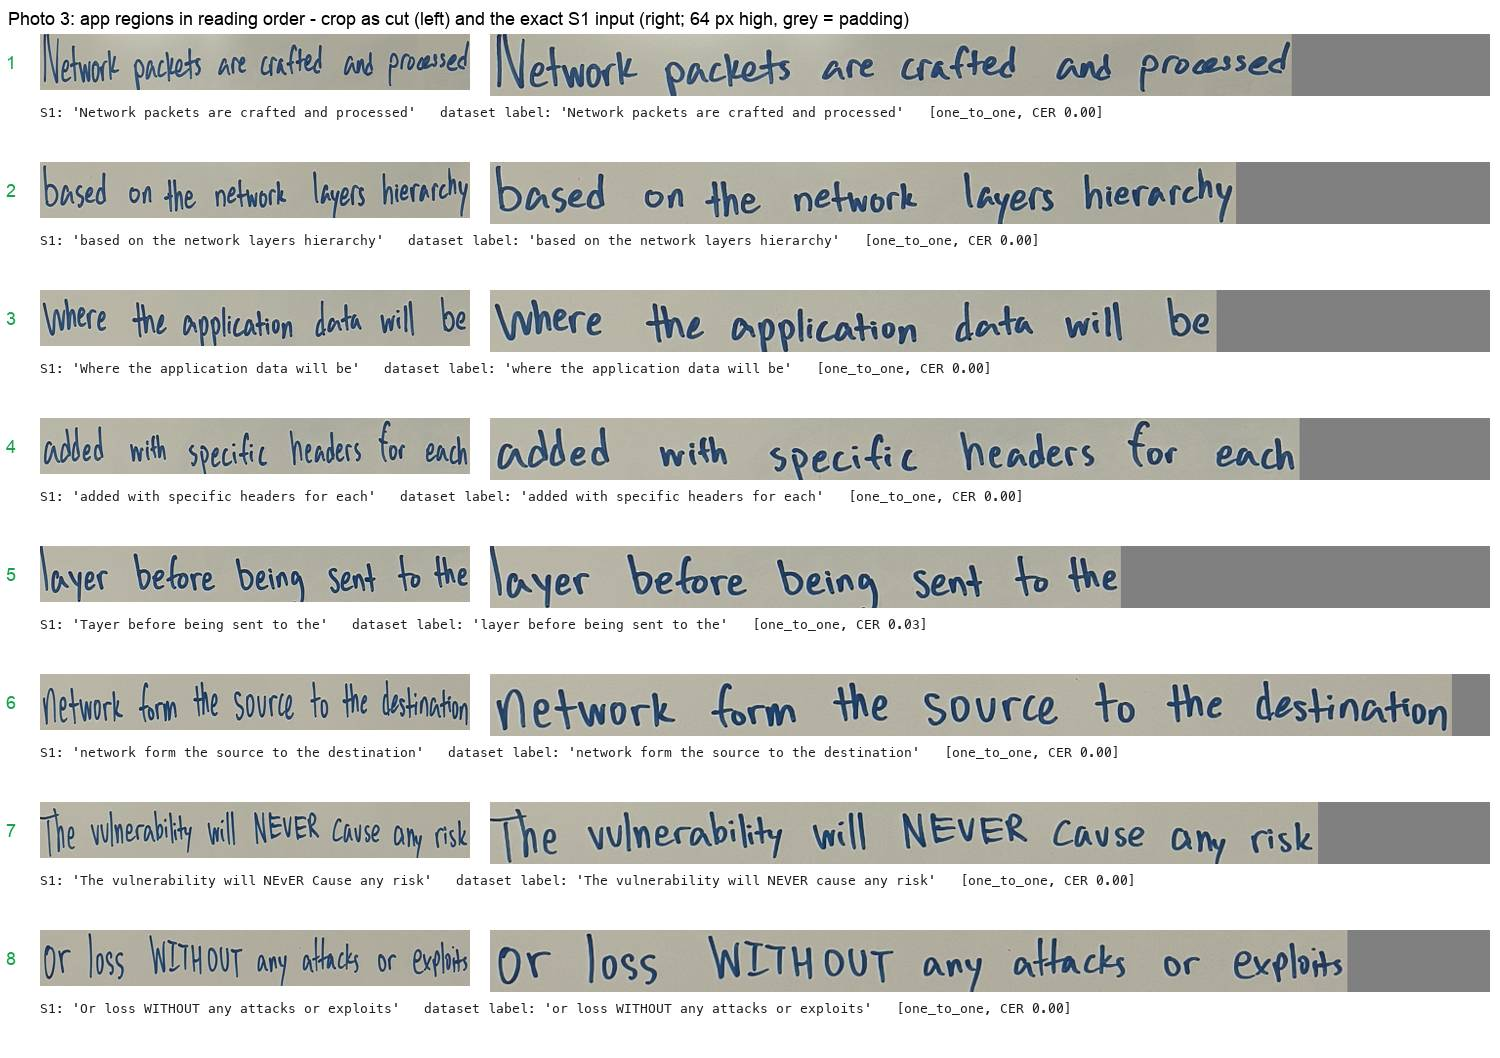

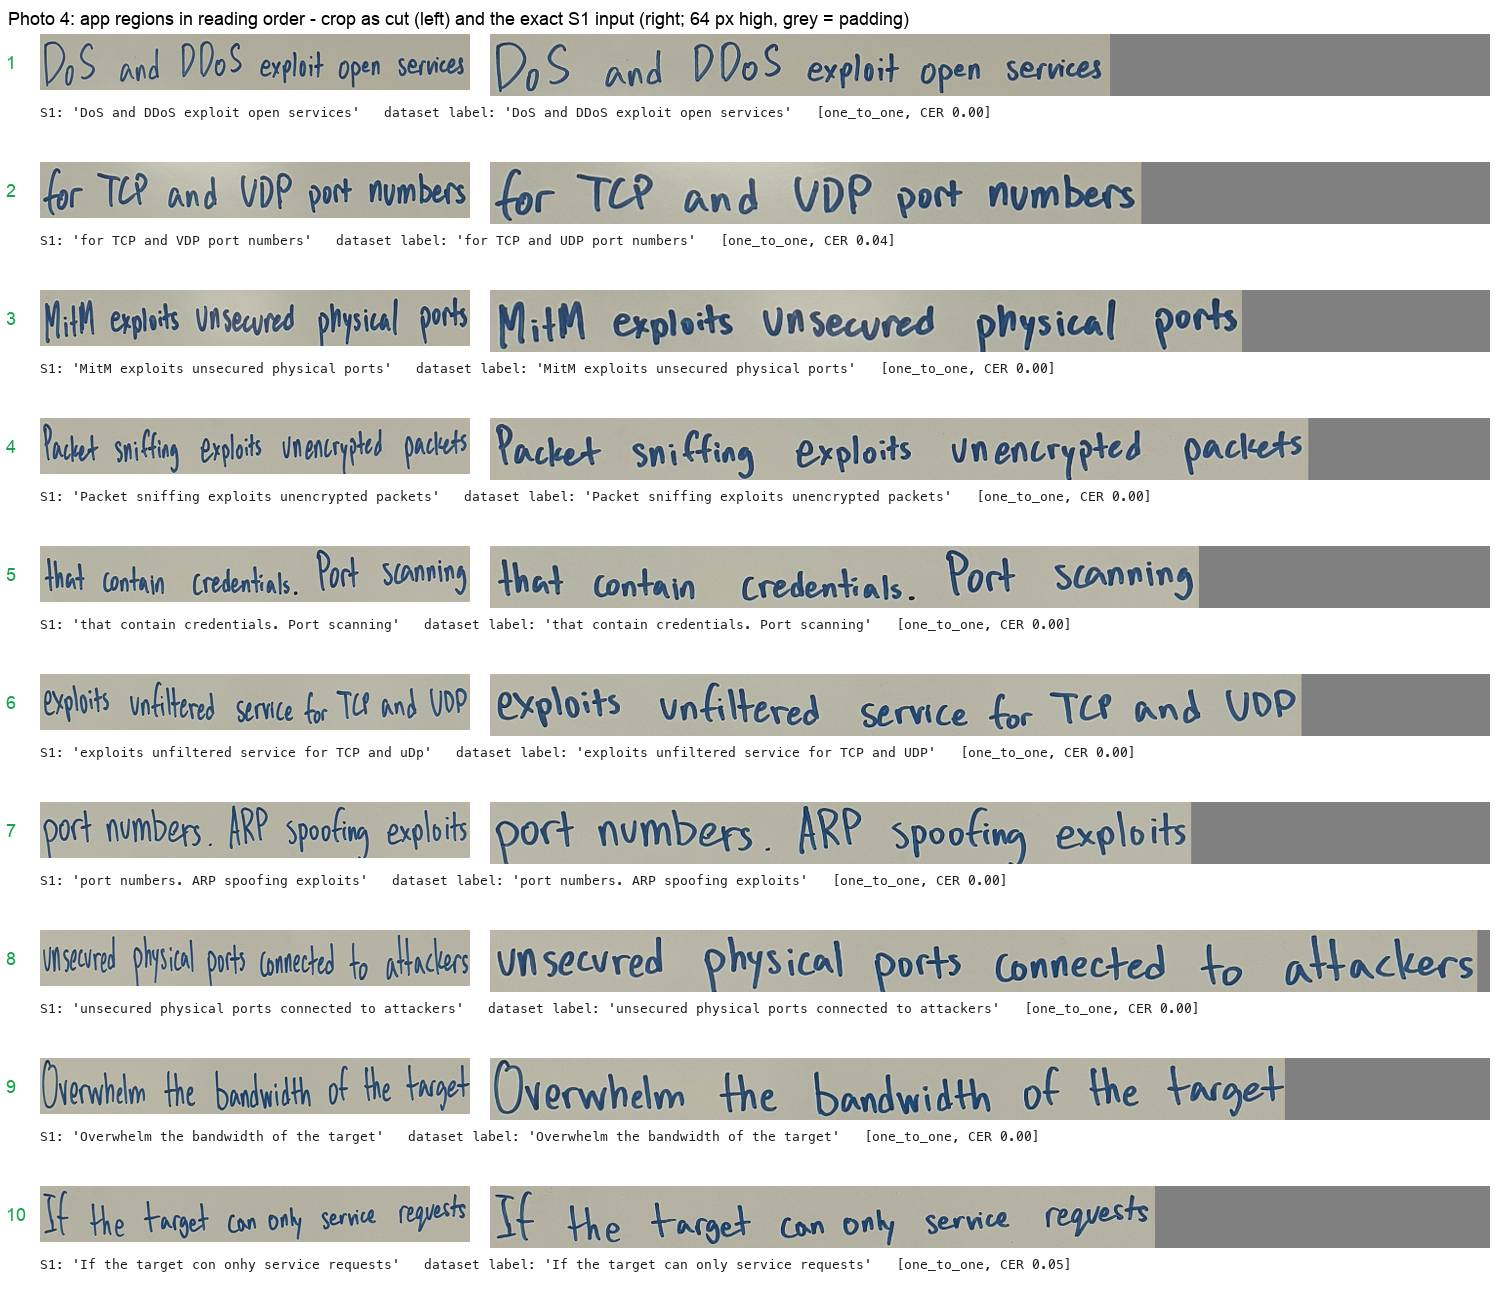

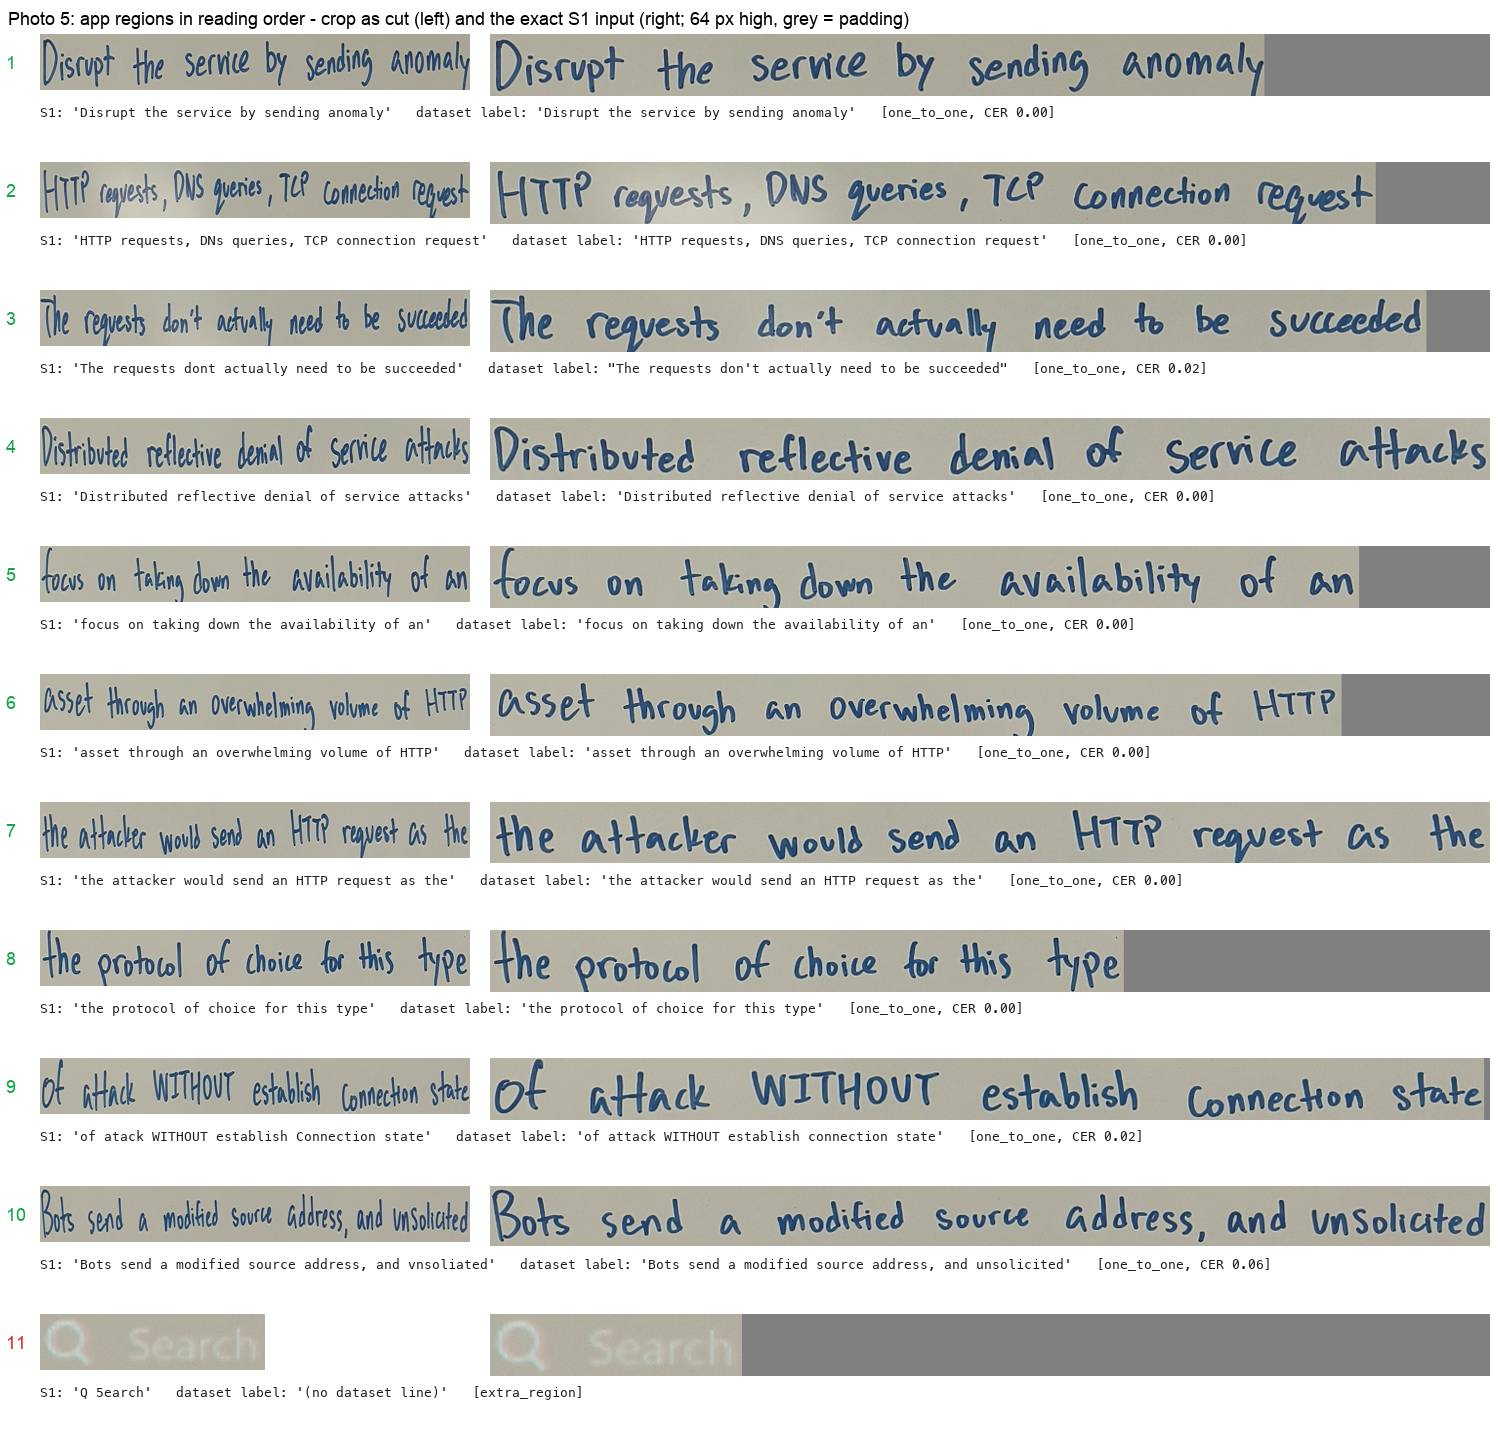

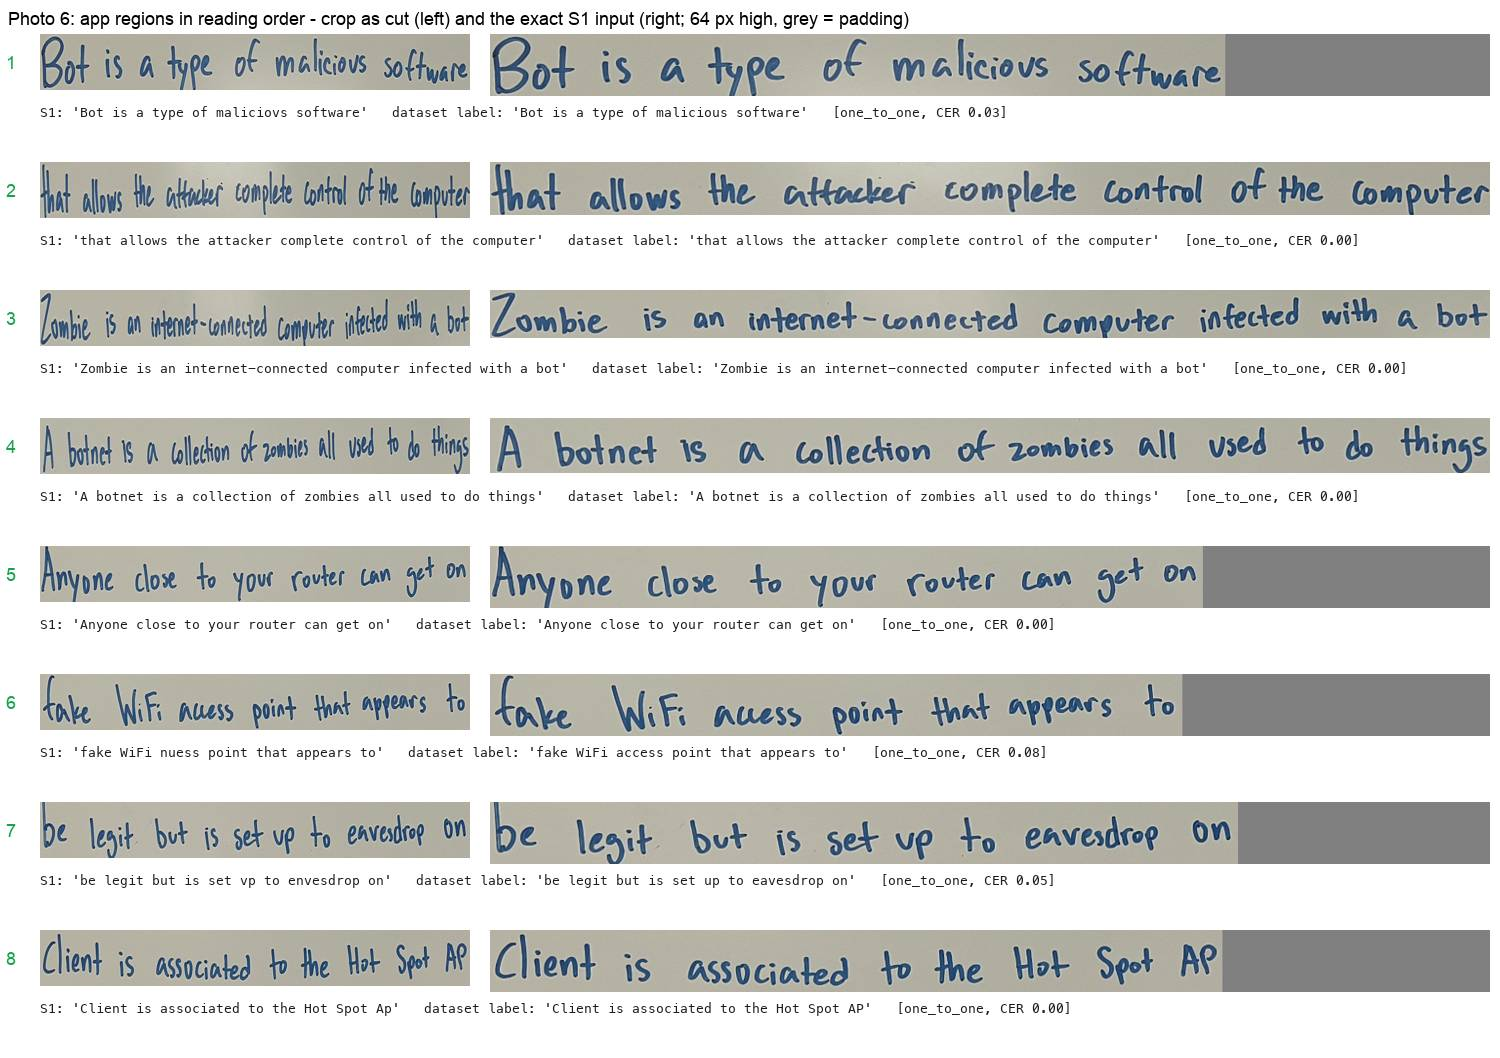

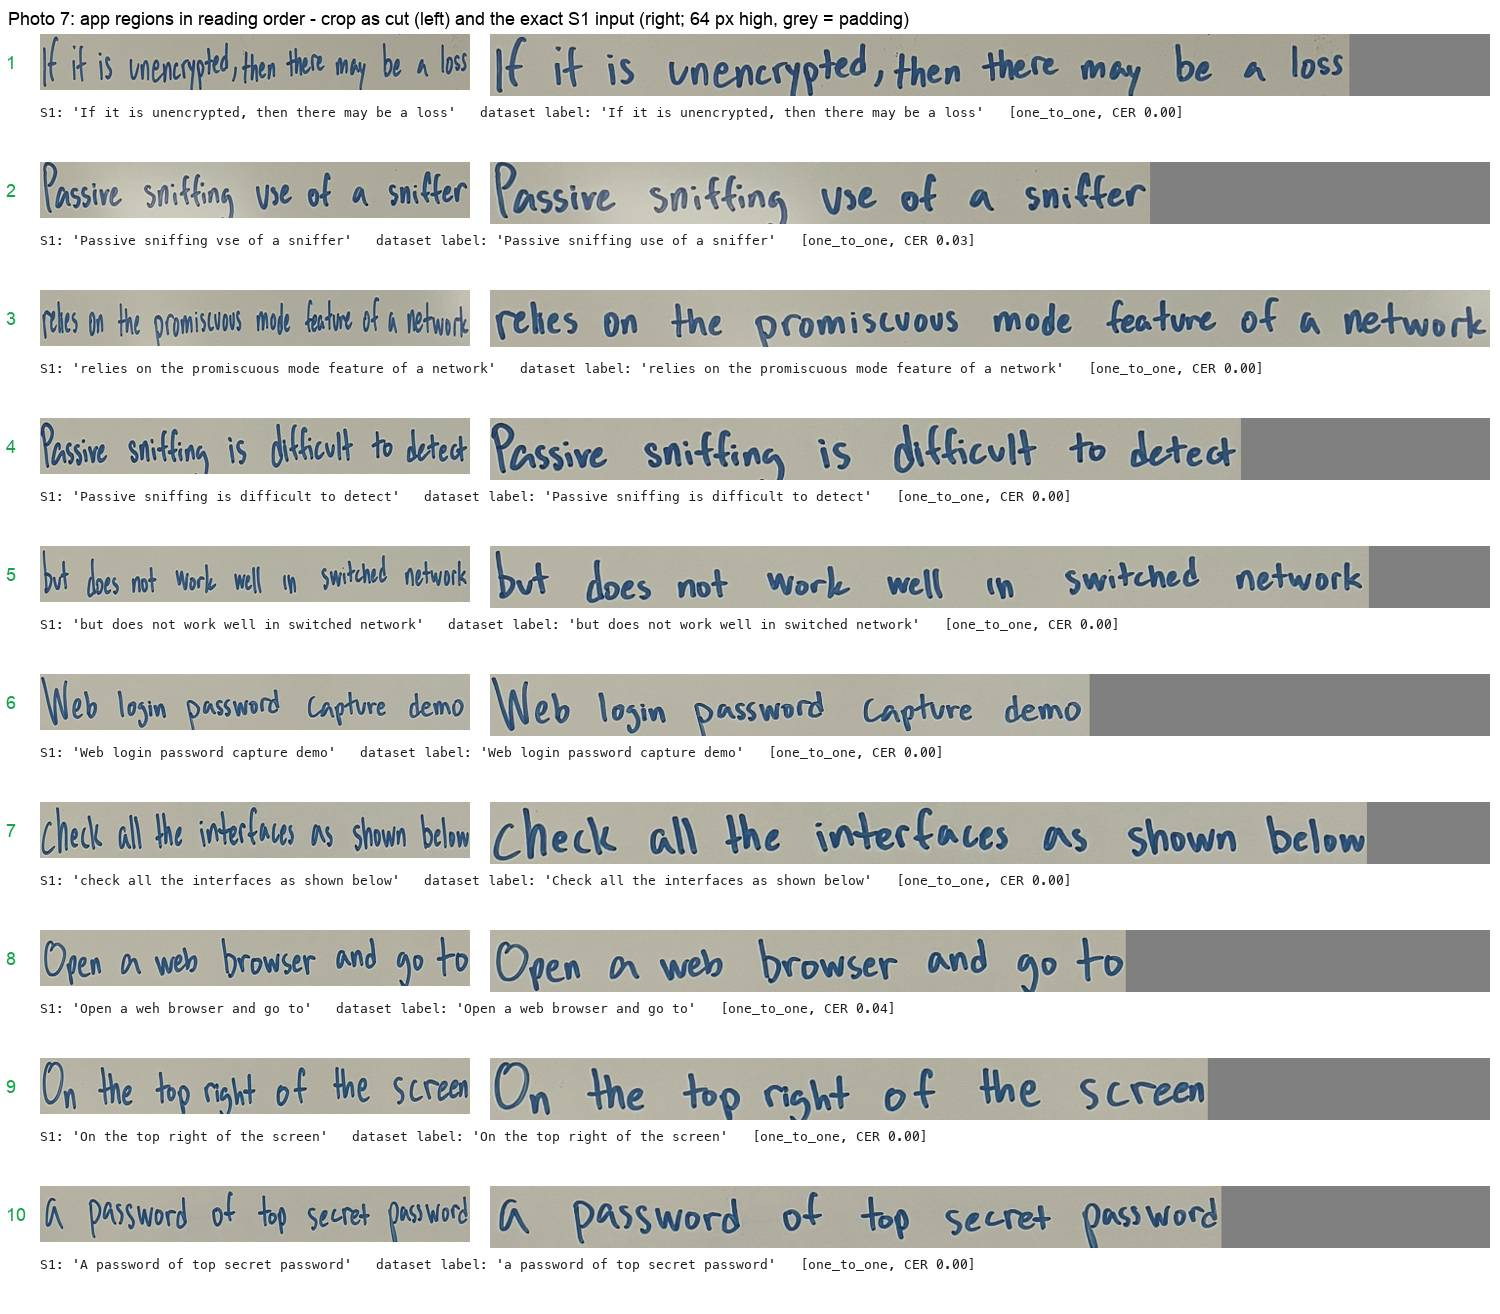

In [4]:
for name in R['visuals']['strips']:
    display(IPImage(filename=str(D/'visuals'/name),width=1200))

## 4. Four versions of every matched line

The contact sheets show all 59 lines, sorted by the change from tightened input to app input. Their captions may truncate long strings. The following viewer shows the full text for any line, with the exact input image available under its expandable control.

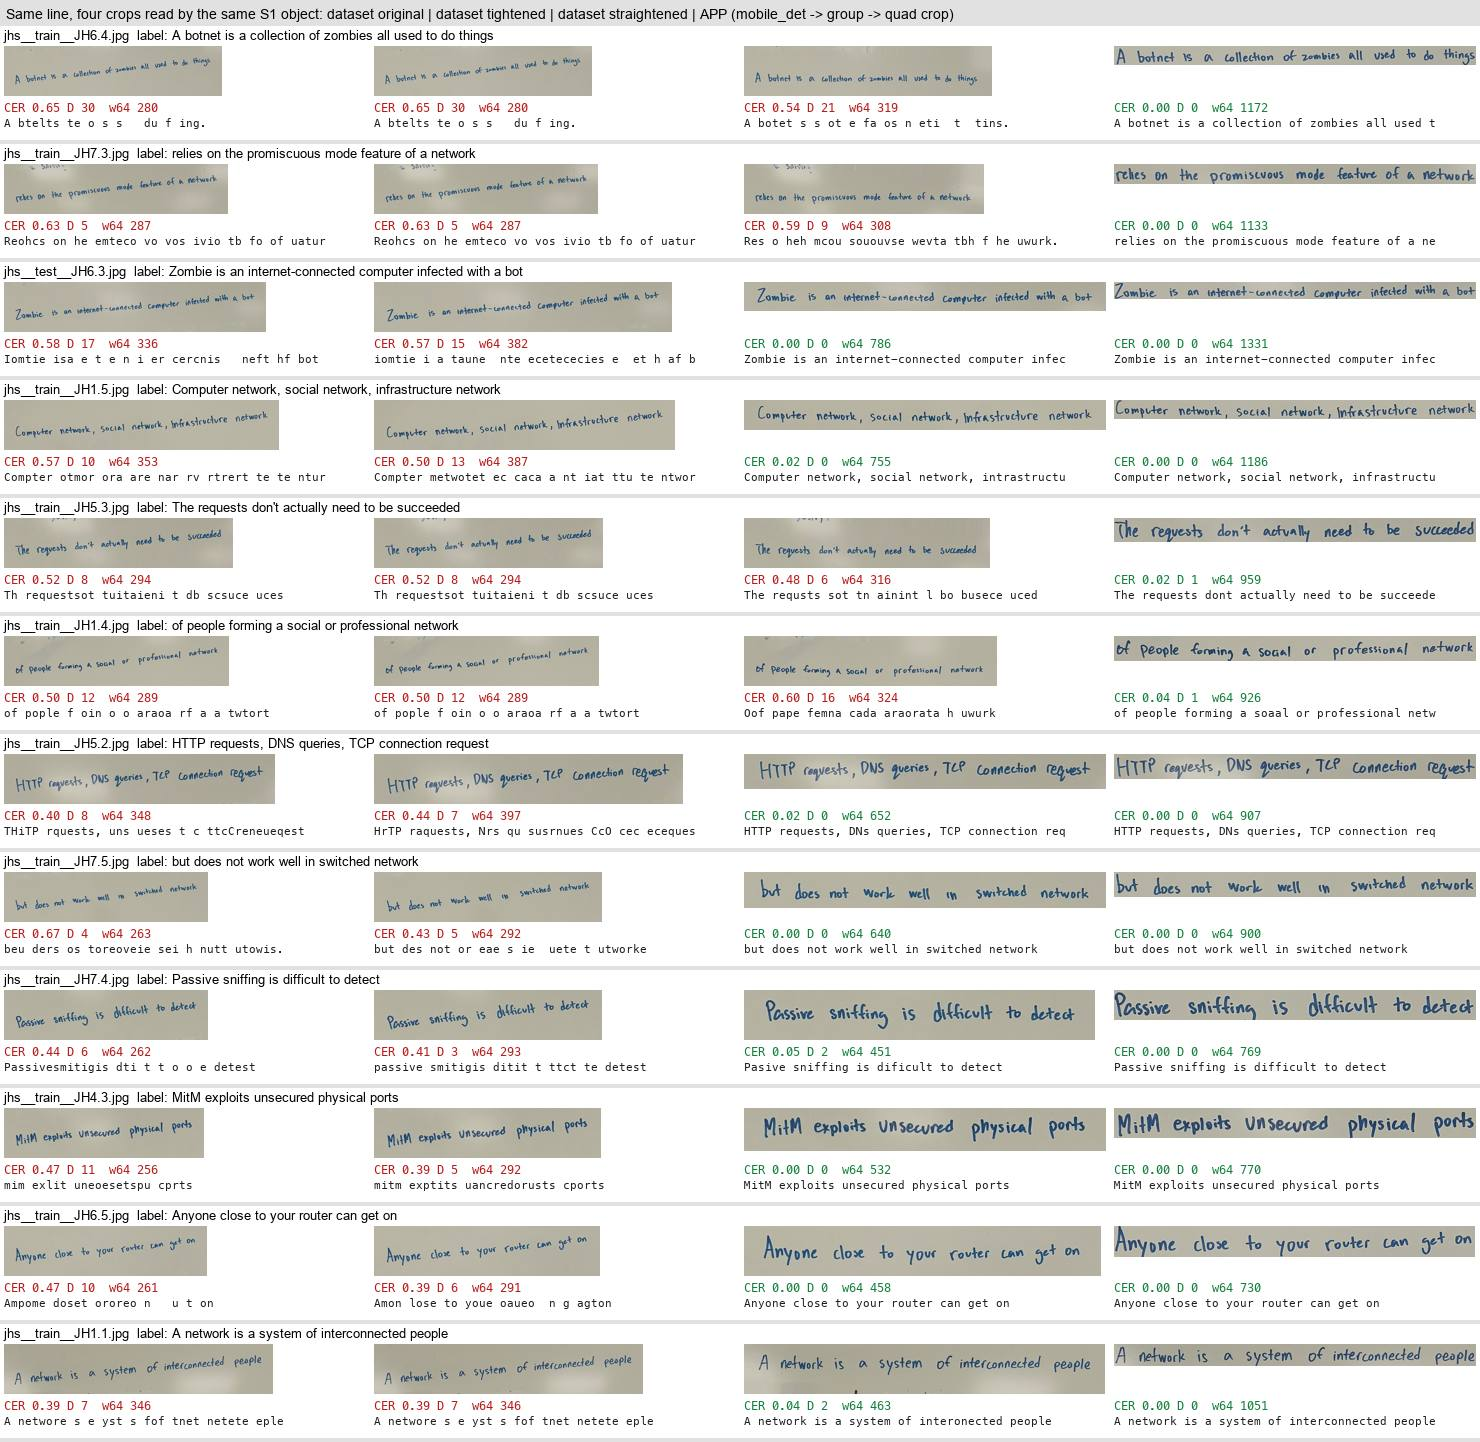

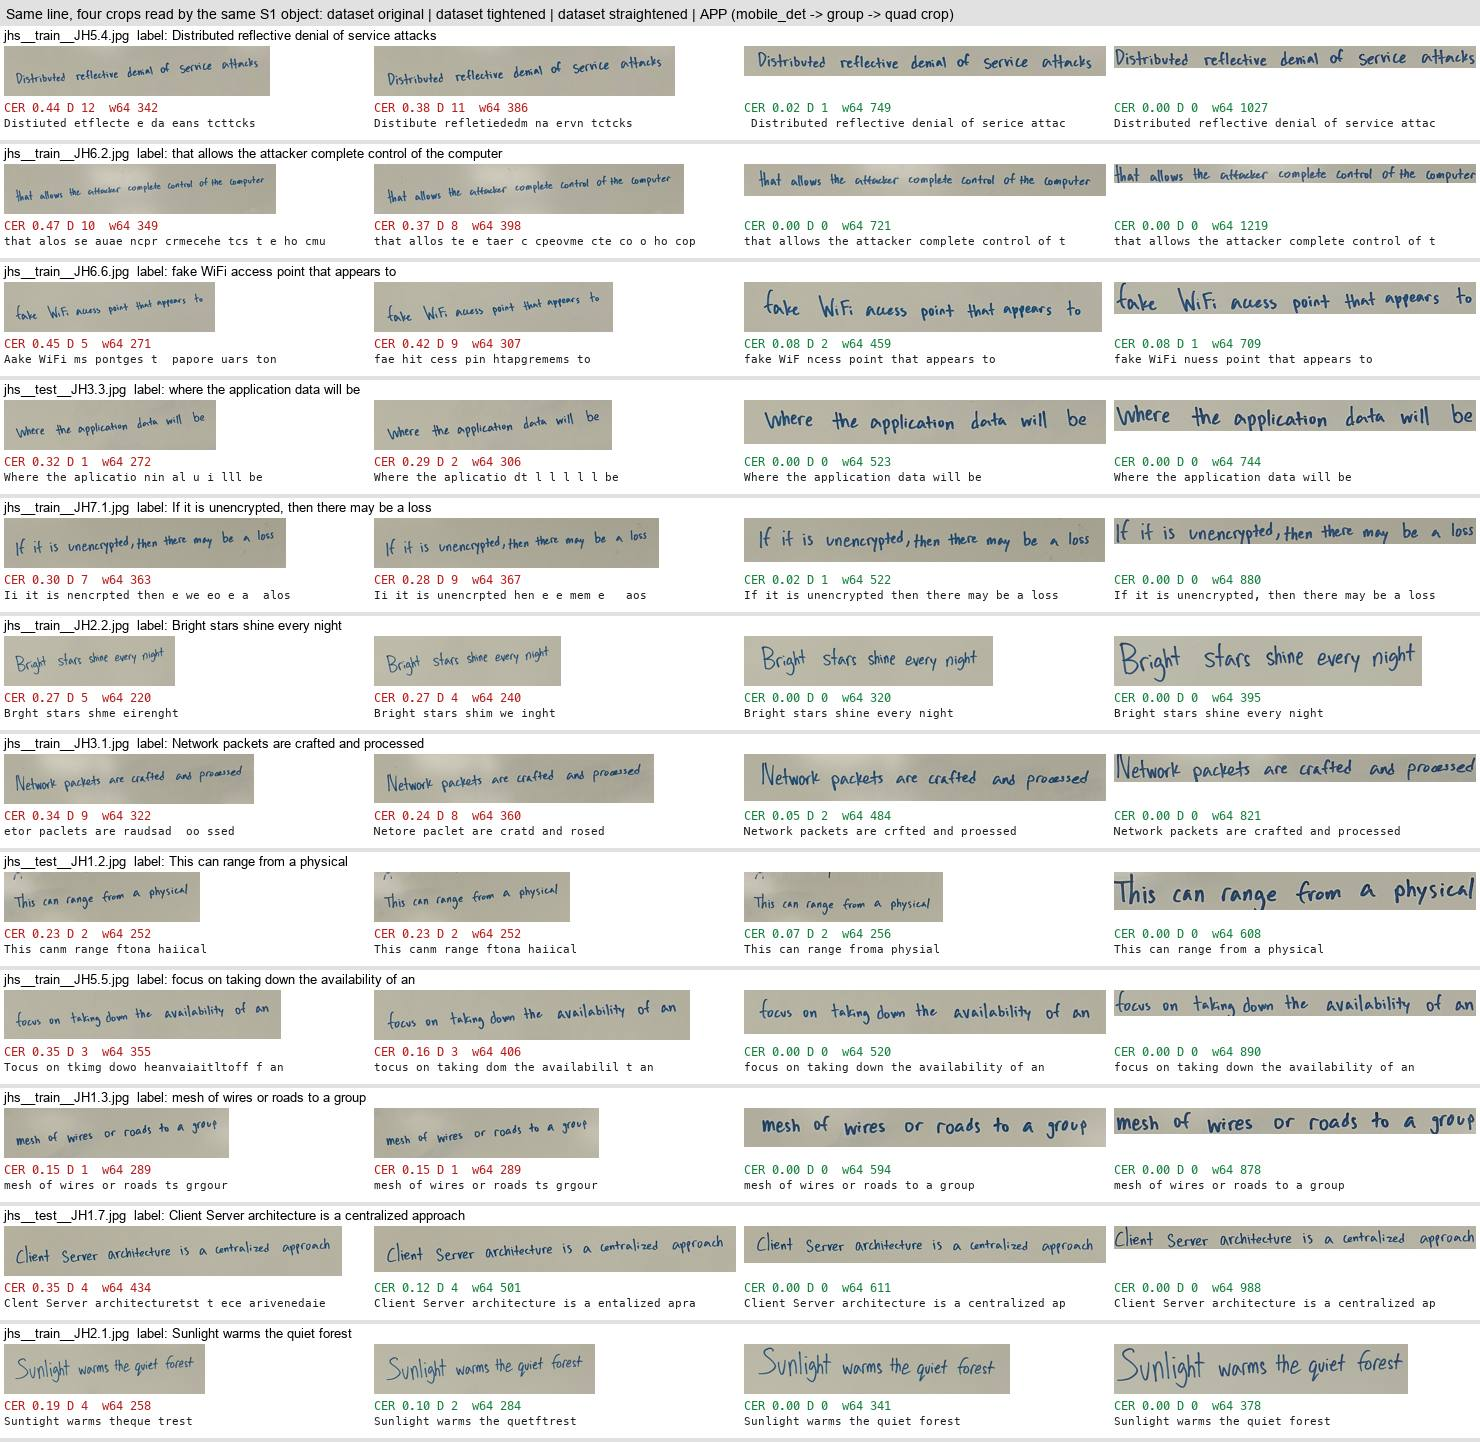

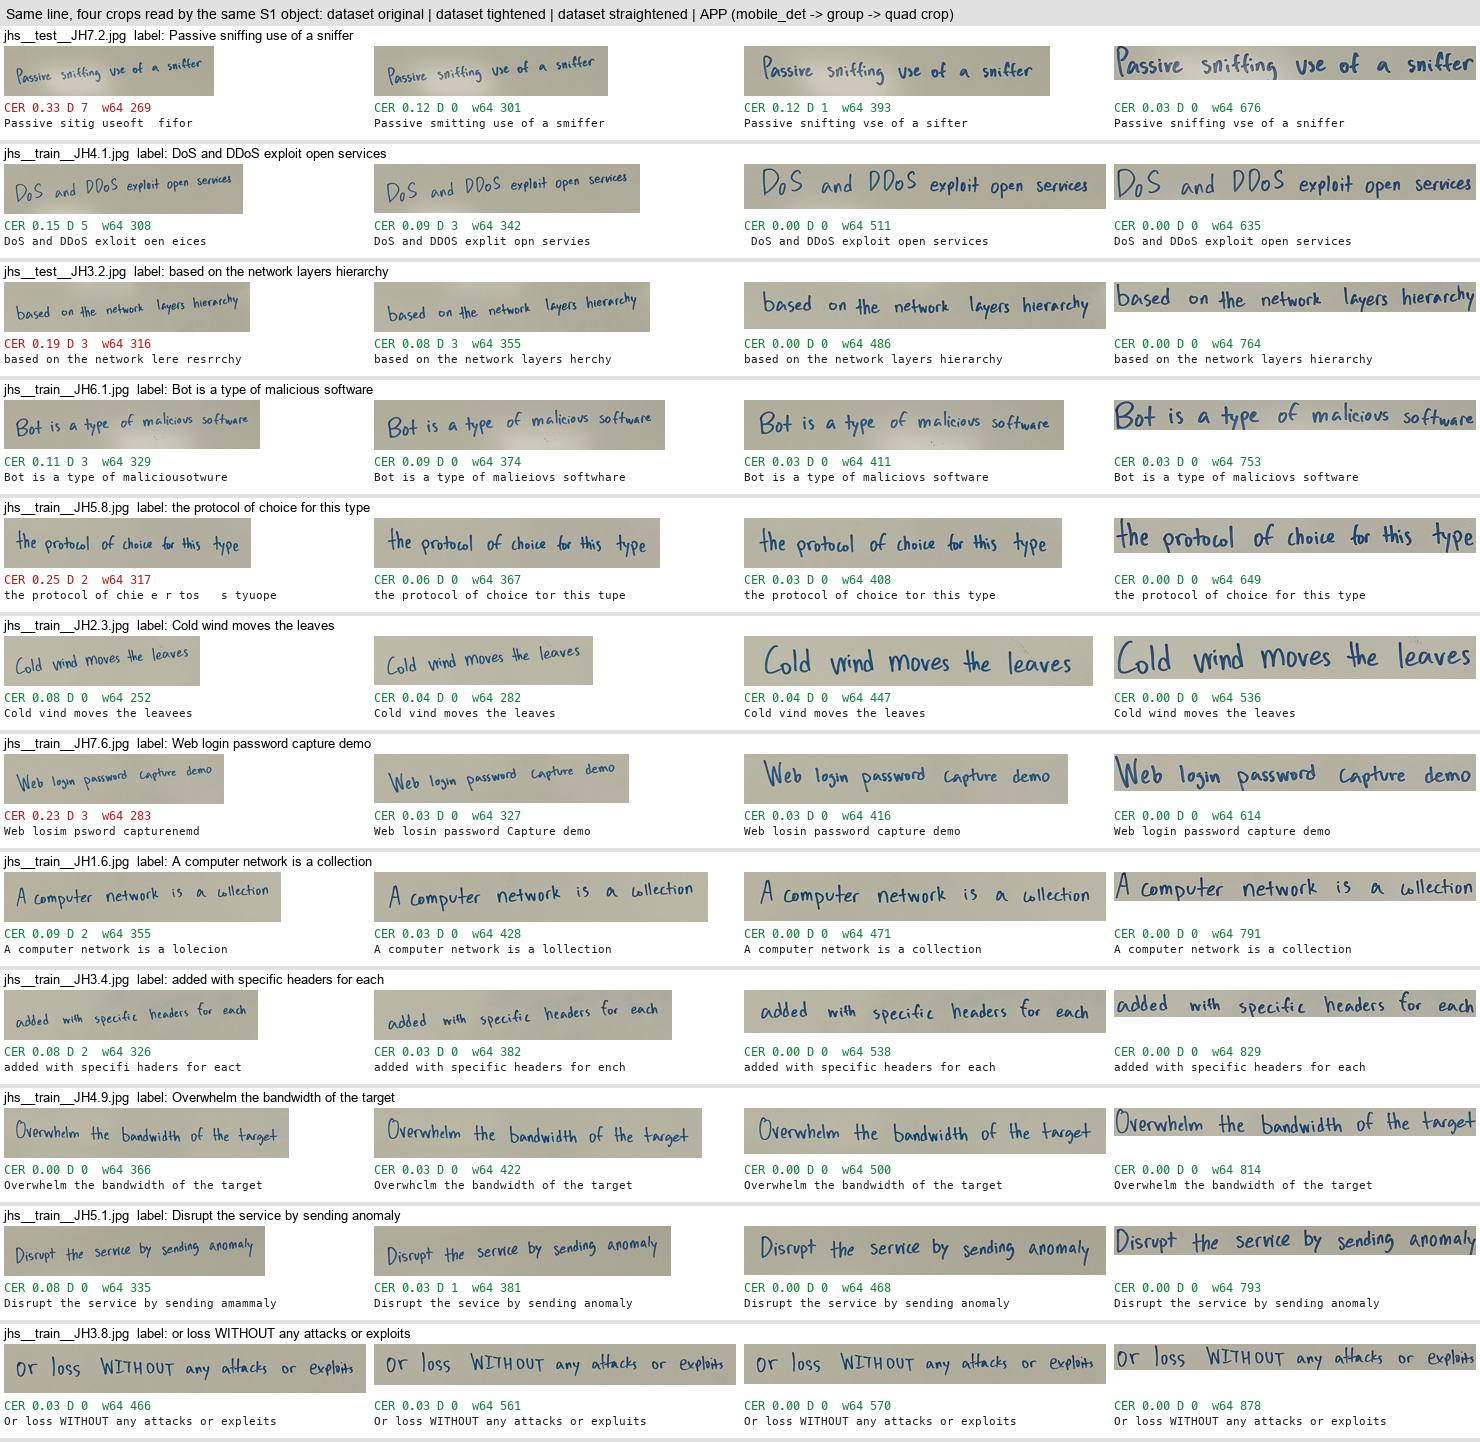

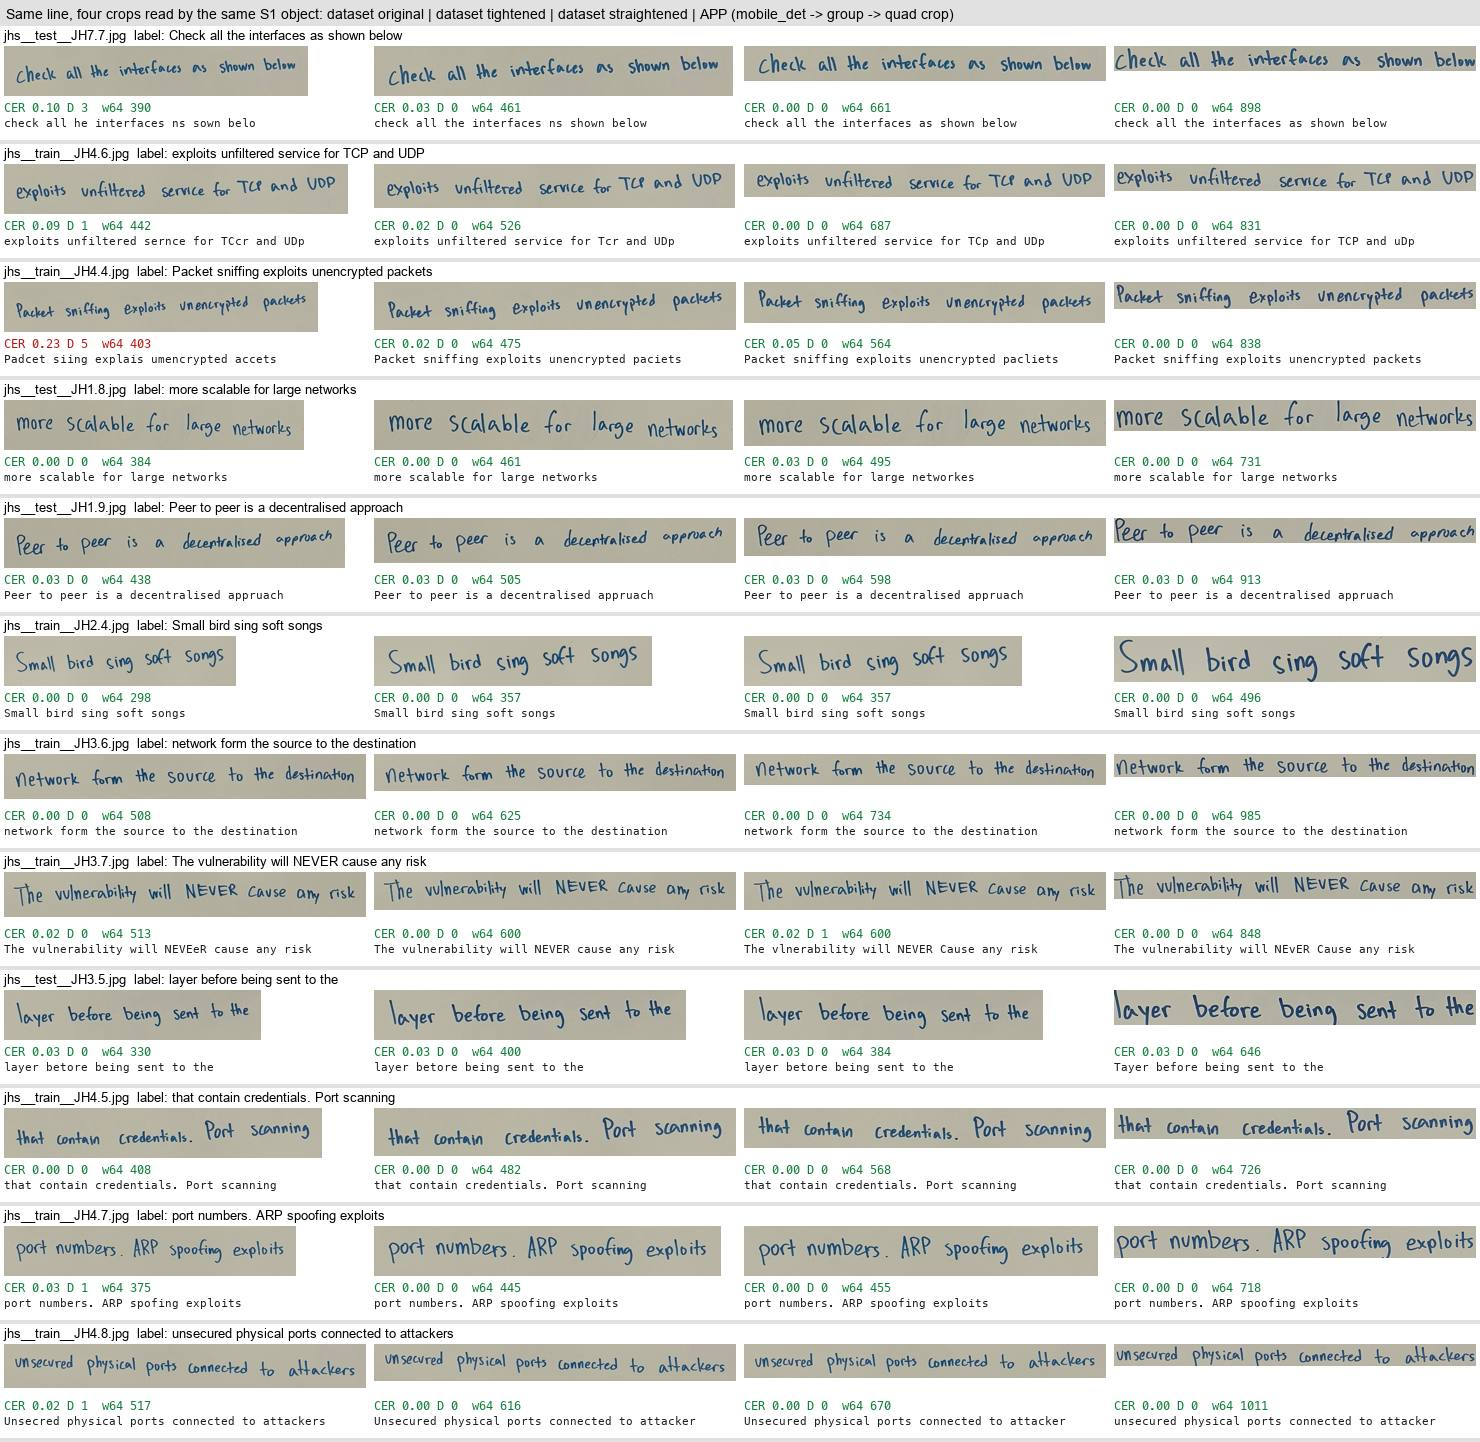

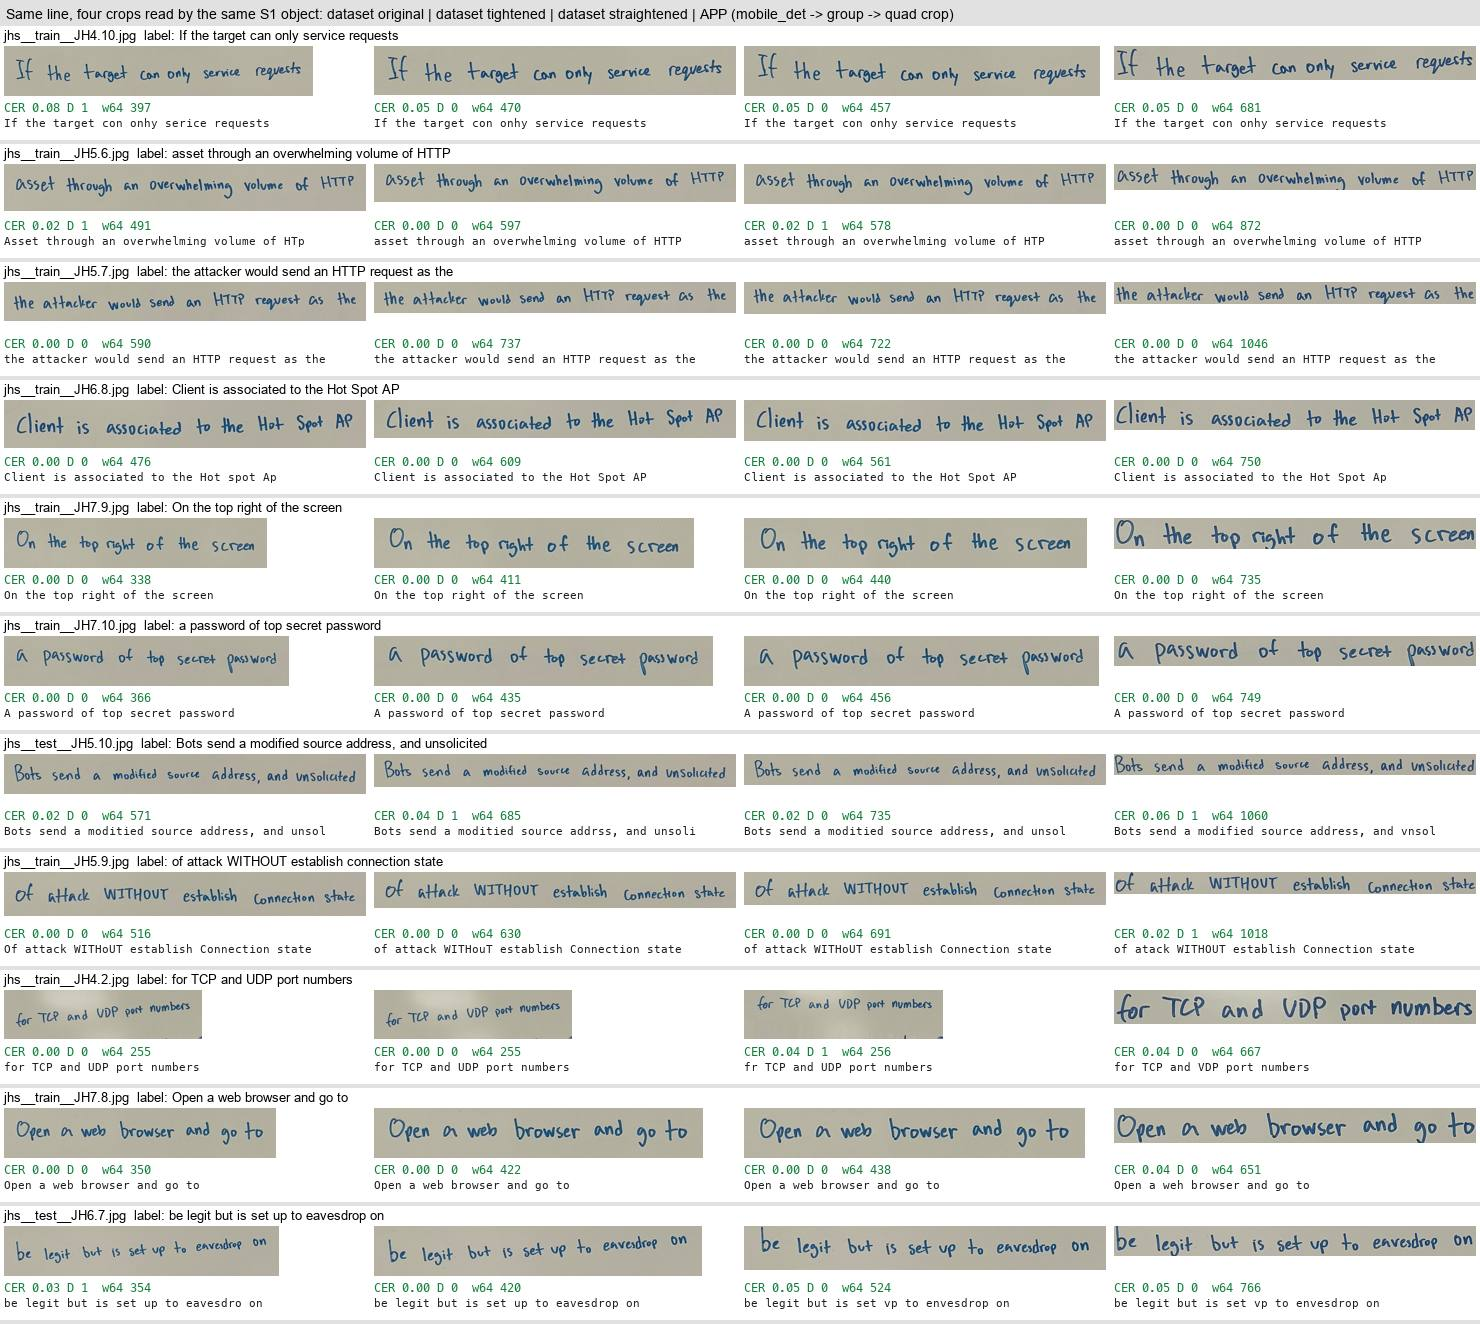

In [5]:
for name in R['visuals']['compare']:
    display(IPImage(filename=str(D/'visuals'/name),width=1300))

Dataset original,Dataset tightened,Dataset straightened,App detector crop
A btelts te o s s du f ing.CER 64.91%; deletions 30,A btelts te o s s du f ing.CER 64.91%; deletions 30,A botet s s ot e fa os n eti t tins.CER 54.39%; deletions 21,A botnet is a collection of zombies all used to do thingsCER 0.00%; deletions 0

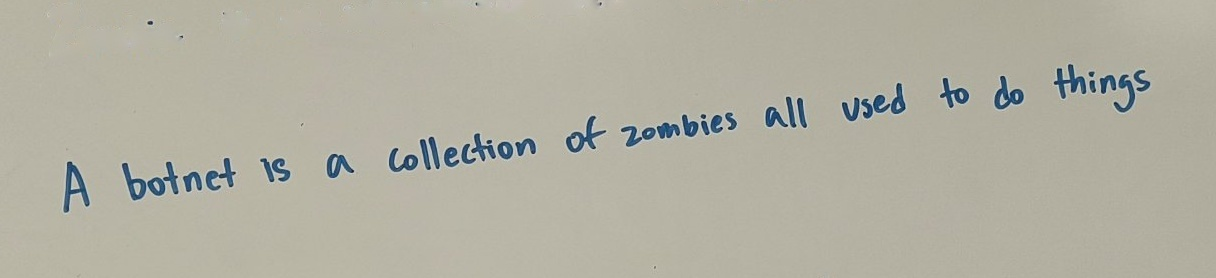
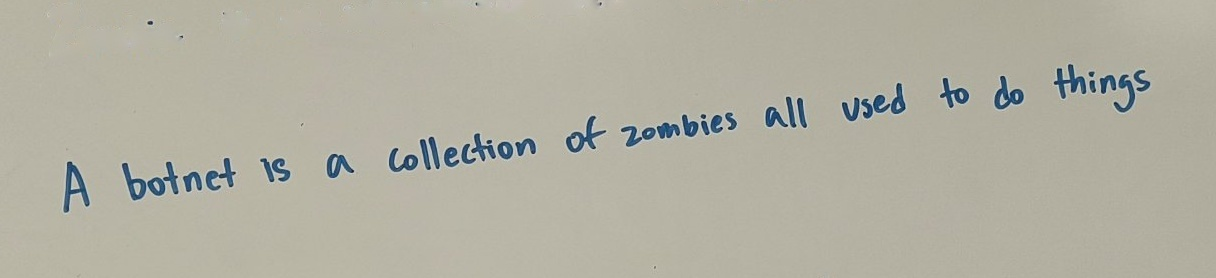
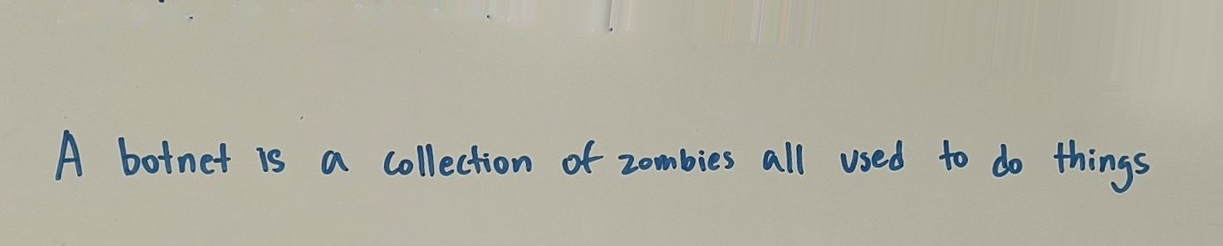
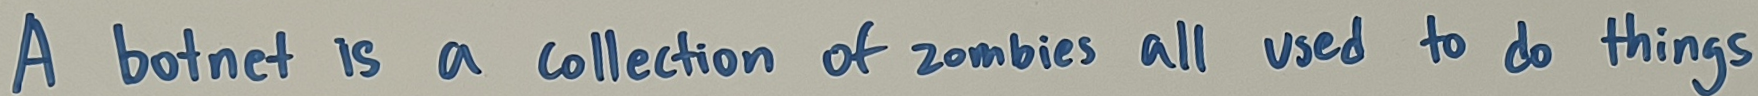
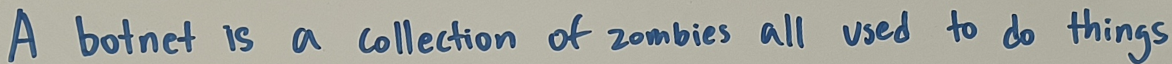

Line ID,Label,App reading,App CER
jhs__train__JH1.1.jpg,A network is a system of interconnected people,A network is a system of interconnected people,0.00%
jhs__test__JH1.2.jpg,This can range from a physical,This can range from a physical,0.00%
jhs__train__JH1.3.jpg,mesh of wires or roads to a group,mesh of wires or roads to a group,0.00%
jhs__train__JH1.4.jpg,of people forming a social or professional network,of people forming a soaal or professional network,4.00%
jhs__train__JH1.5.jpg,"Computer network, social network, infrastructure network","Computer network, social network, infrastructure network",0.00%
jhs__train__JH1.6.jpg,A computer network is a collection,A computer network is a collection,0.00%
jhs__test__JH1.7.jpg,Client Server architecture is a centralized approach,Client Server architecture is a centralized approach,0.00%
jhs__test__JH1.8.jpg,more scalable for large networks,more scalable for large networks,0.00%
jhs__test__JH1.9.jpg,Peer to peer is a decentralised approach,Peer to peer is a decentralised appruach,2.50%
jhs__train__JH2.1.jpg,Sunlight warms the quiet forest,Sunlight warms the quiet forest,0.00%


In [6]:
gallery=(D/'review.html').read_text()
def show_line(line_id):
    found=re.search(r'<article id="line-'+re.escape(html.escape(line_id))+r'">.*?</article>',gallery,re.S)
    if found is None:raise KeyError(line_id)
    display(HTML('<style>table{width:100%;table-layout:fixed}td{vertical-align:top;overflow-wrap:anywhere;padding:8px}img{max-width:100%;height:auto}</style>'+found.group(0)))
LINE='jhs__train__JH6.4.jpg'  # Replace with any line ID from the table below.
show_line(LINE)
table(['Line ID','Label','App reading','App CER'],[[r['line'],r['label'],r['app_text'],f"{r['app']['cer']:.2%}"] for r in sorted(R['one_to_one'],key=lambda r:(r['photo'],r['region']))])

## 5. Unmatched regions are not hidden

Photo 2 includes the black eraser: the detector proposes it, and S1 returns no text. Photo 5 includes the **projected Windows taskbar**, with a magnifier icon and “Search”, read as “Q 5earch”. It is not handwriting; the wider context image below establishes this. These regions are outside the 59-line handwritten-note inventory and are not included in matched-line CER. That is why 0.87% is **not a complete-page accuracy score**.

Correction dated 9 November: an earlier version incorrectly called the Photo 5 projection faint handwriting. Predictions and measured scores are unchanged.

Photo 2 region 5 saved reading: ''
Visual context: Black board eraser; the saved OCR reading is empty.


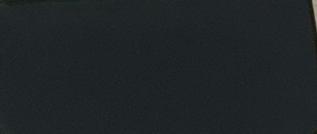

Photo 5 region 11 saved reading: 'Q 5earch'
Visual context: Projected Windows taskbar: magnifier icon and Search, not handwritten notes.


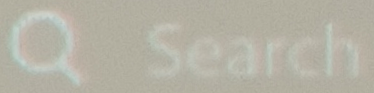

**Photo 5 context: projected Windows taskbar**

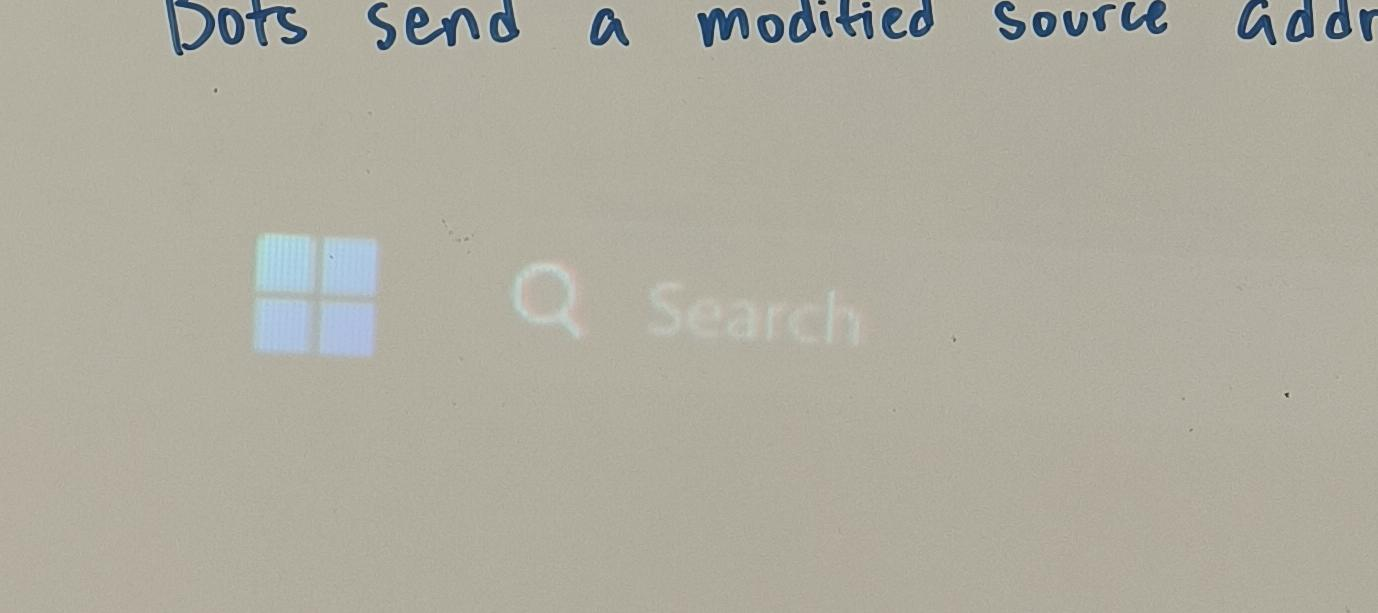

Matched recognition exact lines: 46 / 59
Independent checks: {'photos': 7, 'matched_dataset_lines': 59, 'independent_CER_checks': 236, 'reader_view_pixels_verified': 61, 'all_previous_tight_and_straightened_readings_identical': True, 'source_hashes_and_backend_hashes_match': True, 'paired_photo_intervals_reproduced': True, 'full_page_CER_not_evaluated': True, 'original_app_unchanged': True, 'placement_min_matches': 110, 'placement_min_inliers': 97, 'placement_min_pixel_correlation': 0.8017, 'analysis_sha256': 'f11a9474e235f796c97958bf7fcb41a9b08bf6b01212f006e6633aea762d8696', 'result_sha256': '15881a2c499b99daf44974059735af7a33da665d1362b4c11843ce07bc14c00e', 'recognition_results_sha256_without_visual_context': '470ff513e2b201c8bf462a16404d97b256fde7435156b0f57d9f523635fc6f76', 'visual_context_correction': 'Photo 5 is a projected Windows taskbar, not handwriting; raw OCR and scores preserved.'}


In [7]:
for r in R['extra']:
    print('Photo',r['photo'],'region',r['region'],'saved reading:',repr(r['text']))
    print('Visual context:',r.get('visual_context','Context not classified.'))
    display(IPImage(filename=str(RUN/'crops'/r['files']['crop']),width=650))
display(Markdown('**Photo 5 context: projected Windows taskbar**'))
display(IPImage(filename=str(D/'q_search_check/q_search_context.jpg'),width=900))
print('Matched recognition exact lines:',sum(r['app']['errors']==0 for r in R['one_to_one']),'/ 59')
print('Independent checks:',CHECKS)

## 6. Decision and limits

**Keep the app unchanged for now.** This collection does not justify adding another automatic tightening or deskew stage. The existing detector and rotated crop already avoid most of the problematic upright-dataset geometry.

- These seven photos belong to one inspected development writer; no broad new-writer guarantee follows.
- The 59-line inventory is incomplete for all visible page content. Geometry is assistant-reviewed, not certified independent ground truth.
- The original dataset crops are lower-resolution samples than the full photos. Source detail, interpolation, crop extent and orientation differ together.
- Saved placement records have a minimum of **97 inliers**, not the handoff's claimed 160. The image matches and all four-way comparisons were inspected; do not present them as perfect ground truth.
- The model can accept widths above 1024; 1024 is a minimum here. Wider inputs may produce more than 128 output positions.
- Keep historical results and report the input version explicitly. No labels or previous scores were overwritten.
- No reading-order changes were made or evaluated. That work remains deferred as requested.

Next milestone: freeze the current OCR configuration and confirm on fresh writer/photo groups while progressing local/cloud deployment. Do not start another architecture experiment based on the old loose-crop scores alone.

Full report and self-contained crop gallery: `Assignment/claude_jh_fullphoto_20261109/REPORT.md` and `review.html`.